#Optimizing Long-Context Memory in Large Language Models: An Experimental Comparison of Memory Management Strategies

## 1. Introduction

Large language models can produce useful responses across a conversation, but maintaining relevant information over many sessions is still a challenge. As the conversation becomes longer, the system must decide which information to keep, which information to retrieve, and which information can be removed or compressed.

This project examines how different memory-management strategies affect an LLM's ability to answer questions about long-term conversational history. The study uses the LongMemEval-S Cleaned benchmark and compares five strategies under a controlled experimental setup.

The work is organized as a sequence of reproducible steps. Each step introduces the task, explains the code, and then discusses the results obtained from running it.

## 2. Research Problem

A long conversation may contain useful facts, repeated information, outdated details, and unrelated content. Keeping the full conversation can be expensive or exceed the available context window, while removing information may cause the system to lose facts needed to answer later questions.

The research problem is therefore to determine how different ways of storing and selecting conversational information influence answer quality and resource use.

## 3. Research Aim

The main aim is to compare five memory-management strategies for long-term conversational question answering, using the same benchmark questions and a consistent evaluation procedure.

## 4. Research Objectives

1. Prepare and inspect the LongMemEval-S Cleaned dataset.
2. Implement five memory-management strategies using a consistent experimental setup.
3. Evaluate the strategies on the same questions.
4. Compare their answer quality and retrieval performance.
5. Examine the trade-off between performance and resource use, including token consumption and response time.
6. Document the experimental process so that the results can be reproduced.

## 5. Research Questions

**Main Research Question (MRQ):**

Which memory-management strategy provides the best balance between answer accuracy, evidence recall, token usage, and response latency in long LLM conversations?

**Sub-Research Questions:**

**RQ1.** How does each memory-management strategy perform when answering questions based on long-term conversational history?

**RQ2.** How do the performance and efficiency of memory-management strategies vary across different question types and memory budget levels in terms of answer accuracy, evidence recall, token usage, and response latency?

**RQ3.** What trade-offs exist between answer quality and computational resource consumption across the five memory-management strategies?


## 6. Strategies Included in the Comparison

| Strategy | Description |
|---|---|
| Full Context | Supplies the available conversation history directly, subject to the defined context budget. |
| Trimming | Keeps the most recent conversation content and removes older content when the memory budget is exceeded. |
| Rolling Summary | Maintains an updated compact summary of the conversation history. |
| Vector-Based RAG | Retrieves conversation segments using semantic similarity to the current question. |
| Importance Scoring | Assigns importance scores to memory items and retains items according to a predefined selection rule. |

The implementation details and scoring rules will be defined before the main evaluation. This is important to avoid changing a strategy after seeing its test results.

## 7. Research Methodology

This study follows a comparative experimental design.

- **Dataset:** LongMemEval-S Cleaned.
- **Model:** A Gemini model available through the free API tier. The exact model identifier and settings will be recorded when the API experiment is configured.
- **Implementation language:** Python.
- **Memory storage:** Local files or a lightweight local database, depending on the implementation requirements.
- **Embedding approach:** A locally run embedding model may be used for Vector-Based RAG to avoid relying on a paid embedding API.
- **Comparison:** All five strategies will be evaluated using the same benchmark questions and consistent model settings wherever technically possible.
- **Evaluation:** Answer quality will be assessed alongside relevant resource measures such as input tokens and response time.

The final context budget, sampling plan, prompts, and evaluation procedure will be fixed and documented before the main experiment. Any model or API limitations will also be reported rather than hidden.

## 8. Dataset

The study uses `longmemeval_s_cleaned.json` from the `xiaowu0162/longmemeval-cleaned` dataset repository on Hugging Face.

The file contains 500 benchmark questions. Each record includes the question, its type, the reference answer, session identifiers, session dates, and the conversation sessions used as the context for answering.

The reference answer and evidence-session identifiers are reserved for evaluation and validation. They must not be supplied to a memory strategy as input when it generates an answer.

## 9. Notebook Workflow

1. Import the required libraries.
2. Load the dataset.
3. Inspect the dataset structure and validate its basic integrity.
4. Explore question types and conversation lengths.
5. Define the experimental sample and shared constraints.
6. Implement the five memory strategies.
7. Run the experiments.
8. Evaluate and compare the results.
9. Discuss limitations and conclusions.

## Importing the Required Libraries

The first step is to import the Python libraries needed for loading, inspecting, and analyzing the dataset. We use standard libraries for JSON files and file paths, together with Pandas for tabular summaries and Matplotlib for later visualizations.

This step only prepares the working environment; it does not modify the dataset.

In [1]:
import json
import os
from pathlib import Path
from collections import Counter

import pandas as pd
import matplotlib.pyplot as plt

print("Libraries imported successfully.")

Libraries imported successfully.


## Loading the Dataset

The dataset is stored as a JSON file. In this step, the file is loaded into Python and its top-level structure is checked.

If you are using Google Colab, run the upload cell below and select `longmemeval_s_cleaned.json`. If the file is already available in the notebook's working directory, you can skip the upload cell and set the correct file path directly.

In [2]:
# Google Colab upload option
from google.colab import files

uploaded = files.upload()

# Use the uploaded filename
DATA_PATH = next(iter(uploaded))

print(f"Selected file: {DATA_PATH}")
print(f"File size: {os.path.getsize(DATA_PATH) / (1024**2):.2f} MB")

Saving longmemeval_s_cleaned.json to longmemeval_s_cleaned.json
Selected file: longmemeval_s_cleaned.json
File size: 264.53 MB


**Alternative for a local Jupyter environment:** If the JSON file is in the same folder as this notebook, use the following cell instead of the Colab upload cell.

In [3]:
# Uncomment and use this in local Jupyter if needed:
# DATA_PATH = "longmemeval_s_cleaned.json"
# print(f"File exists: {Path(DATA_PATH).exists()}")

In [4]:
with open(DATA_PATH, "r", encoding="utf-8") as file:
    data = json.load(file)

print("Dataset loaded successfully.")
print("Top-level data type:", type(data).__name__)
print("Number of records:", len(data))

Dataset loaded successfully.
Top-level data type: list
Number of records: 500


### Inspecting One Record

Before processing all records, it is useful to inspect one example. This helps us understand the available fields and the way conversation sessions are represented.

The example is displayed for inspection only. The reference answer will not be included in the input sent to the model during the experiments.

In [5]:
# Display the keys and a short preview of the first record
first_record = data[0]

print("Available fields:")
print(list(first_record.keys()))

print("\nQuestion ID:", first_record["question_id"])
print("Question type:", first_record["question_type"])
print("Question:", first_record["question"])
print("Number of sessions:", len(first_record["haystack_sessions"]))
print("Number of evidence sessions:", len(first_record["answer_session_ids"]))

Available fields:
['question_id', 'question_type', 'question', 'question_date', 'answer', 'answer_session_ids', 'haystack_dates', 'haystack_session_ids', 'haystack_sessions']

Question ID: e47becba
Question type: single-session-user
Question: What degree did I graduate with?
Number of sessions: 53
Number of evidence sessions: 1


## Basic Dataset Validation

Before using the benchmark, we check several structural properties:

- The dataset contains 500 records.
- Each question has a unique identifier.
- Questions have non-empty reference answers.
- The number of session dates, session identifiers, and session contents is consistent within each record.
- Every evidence-session identifier is present in the corresponding list of session identifiers.

These checks assess basic file integrity. They do not prove that every reference answer is semantically correct; they only verify that the dataset structure is consistent for the next stages.

In [6]:
required_fields = {
    "question_id",
    "question_type",
    "question",
    "question_date",
    "answer",
    "answer_session_ids",
    "haystack_dates",
    "haystack_session_ids",
    "haystack_sessions",
}

missing_field_records = []
question_ids = [record.get("question_id") for record in data]

for index, record in enumerate(data):
    missing = required_fields - set(record.keys())
    if missing:
        missing_field_records.append((index, sorted(missing)))

duplicate_id_count = len(question_ids) - len(set(question_ids))

empty_question_count = sum(
    not isinstance(record.get("question"), str)
    or not record["question"].strip()
    for record in data
)

empty_answer_count = sum(
    answer is None
    or (isinstance(answer, str) and not answer.strip())
    for answer in (record.get("answer") for record in data)
)

session_length_mismatches = []
missing_evidence_ids = []

for index, record in enumerate(data):
    dates = record.get("haystack_dates", [])
    session_ids = record.get("haystack_session_ids", [])
    sessions = record.get("haystack_sessions", [])

    if not (len(dates) == len(session_ids) == len(sessions)):
        session_length_mismatches.append(index)

    if not set(record.get("answer_session_ids", [])).issubset(set(session_ids)):
        missing_evidence_ids.append(index)

print("Number of records:", len(data))
print("Records with missing required fields:", len(missing_field_records))
print("Duplicate question IDs:", duplicate_id_count)
print("Empty questions:", empty_question_count)
print("Empty reference answers:", empty_answer_count)
print("Records with inconsistent session-list lengths:", len(session_length_mismatches))
print("Records with missing evidence-session IDs:", len(missing_evidence_ids))

Number of records: 500
Records with missing required fields: 0
Duplicate question IDs: 0
Empty questions: 0
Empty reference answers: 0
Records with inconsistent session-list lengths: 0
Records with missing evidence-session IDs: 0


### Results Interpretation

The validation results confirmed that all 500 records were loaded successfully. No missing required fields, duplicate question IDs, or empty questions were found. All session dates, IDs, and conversation contents were consistent, and all evidence-session IDs were available.

After correcting the answer validation code to accept numerical answers as well as text, no empty reference answers were detected.

Overall, the dataset passed all the structural checks and is ready for the next stage of analysis.

## Distribution of Question Types

LongMemEval contains different question types that test different aspects of conversational memory. We count the number of records in each category and calculate their percentage of the full dataset.

This distribution will help us understand the benchmark composition and plan a representative pilot sample.

In [7]:
question_type_counts = Counter(
    record["question_type"] for record in data
)

question_type_summary = pd.DataFrame(
    question_type_counts.items(),
    columns=["Question Type", "Number of Questions"]
)

question_type_summary["Percentage"] = (
    question_type_summary["Number of Questions"] / len(data) * 100
).round(2)

question_type_summary = question_type_summary.sort_values(
    "Number of Questions", ascending=False
).reset_index(drop=True)

display(question_type_summary.style.hide(axis="index"))

Question Type,Number of Questions,Percentage
multi-session,133,26.600000
temporal-reasoning,133,26.600000
knowledge-update,78,15.600000
single-session-user,70,14.000000
single-session-assistant,56,11.200000
single-session-preference,30,6.000000


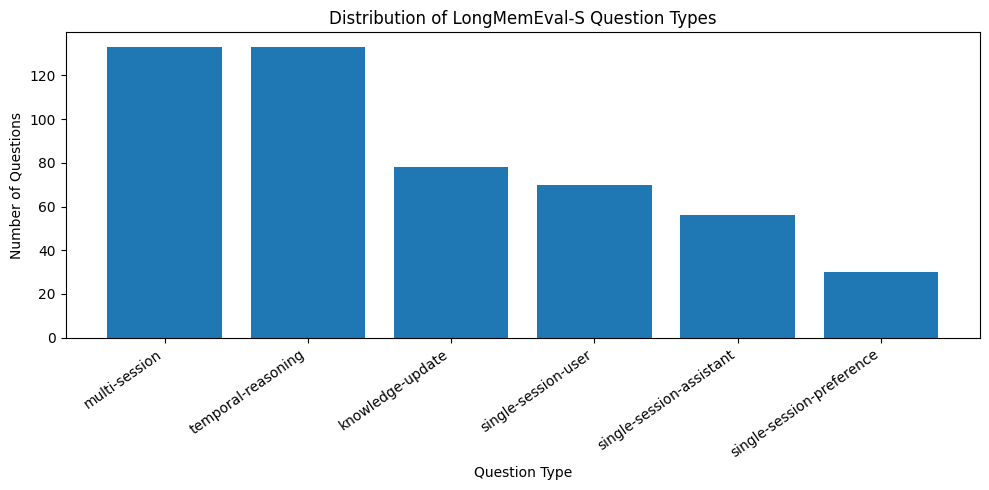

In [8]:
plt.figure(figsize=(10, 5))
plt.bar(
    question_type_summary["Question Type"],
    question_type_summary["Number of Questions"]
)
plt.title("Distribution of LongMemEval-S Question Types")
plt.xlabel("Question Type")
plt.ylabel("Number of Questions")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()

### Results Interpretation

The dataset contains six question types. Multi-session and temporal-reasoning questions are the largest categories, with 133 questions each (26.6%). Single-session-preference is the smallest category, with 30 questions (6%).

This distribution shows that the benchmark places considerable emphasis on retrieving information across multiple sessions and reasoning about time. Therefore, we will consider the different question types separately when comparing the five memory strategies.

## Conversation Length Analysis

The number of sessions and messages can vary significantly between benchmark questions. Understanding these differences is important before defining the memory limits used in the experiments. In this section, we examine the conversation lengths to obtain a clearer picture of the dataset size and structure.

In [9]:
session_counts = []
message_counts = []

for record in data:
    sessions = record["haystack_sessions"]

    session_counts.append(len(sessions))

    total_messages = sum(
        len(session) for session in sessions
    )
    message_counts.append(total_messages)

conversation_stats = pd.DataFrame({
    "Number of Sessions": session_counts,
    "Number of Messages": message_counts
})

display(conversation_stats.describe().round(2))

,Number of Sessions,Number of Messages
count,500.00,500.00
mean,47.73,493.50
std,3.47,31.23
min,38.00,396.00
25%,45.00,474.00
50%,48.00,491.00
75%,50.00,512.00
max,62.00,616.00


### Results Interpretation

The dataset contains 500 conversation records, with an average of 47.73 sessions and 493.50 messages per record. The number of sessions ranges from 38 to 62, while the number of messages ranges from 396 to 616.

The standard deviations (3.47 sessions and 31.23 messages) indicate relatively limited variation in conversation length across the records.

These results show that LongMemEval-S provides consistently long conversation histories, making it suitable for evaluating memory-management strategies under limited context conditions.

## Conversation Size and Chronological Analysis

### Introduction

In this section, we examine the amount of text contained in each conversation record. We calculate the total number of words and characters to understand the variation in conversation size.

We also check whether the sessions are already arranged chronologically. This is important because some memory strategies, such as Trimming and Rolling Summary, depend on the order of previous conversations.

### Measuring Conversation Size

This step calculates the total number of words and characters in each conversation record.

In [10]:
import re

word_counts = []
character_counts = []

for record in data:
    full_text = []

    for session in record["haystack_sessions"]:
        for message in session:
            full_text.append(message["content"])

    conversation_text = " ".join(full_text)

    word_counts.append(
        len(re.findall(r"\b\w+\b", conversation_text))
    )

    character_counts.append(len(conversation_text))


conversation_size = pd.DataFrame({
    "Number of Words": word_counts,
    "Number of Characters": character_counts
})

display(conversation_size.describe().round(2))

,Number of Words,Number of Characters
count,500.00,500.00
mean,80312.81,489790.21
std,1457.66,9238.69
min,74629.00,455470.00
25%,79336.50,483687.50
50%,80475.00,490350.00
75%,81359.25,496564.00
max,83609.00,514447.00


### Checking Chronological Order

Here, we check whether the sessions in each record are arranged from the earliest date to the latest date.

In [11]:
from datetime import datetime

chronological_records = 0
non_chronological_records = 0

for record in data:
    dates = [
        datetime.strptime(date, "%Y/%m/%d (%a) %H:%M")
        for date in record["haystack_dates"]
    ]

    if dates == sorted(dates):
        chronological_records += 1
    else:
        non_chronological_records += 1

print("Chronologically ordered records:", chronological_records)
print("Non-chronologically ordered records:", non_chronological_records)

Chronologically ordered records: 289
Non-chronologically ordered records: 211


###  Results Interpretation

The dataset contains 500 records, with an average of approximately 80,313 words and 489,790 characters per record. The word count ranges from 74,629 to 83,609, indicating that all records contain relatively large conversation histories.

The chronological analysis showed that 289 records (57.8%) are already ordered chronologically, while 211 records (42.2%) are not. Therefore, the sessions must be sorted by their timestamps before applying the memory-management strategies. This is important to ensure that recent information and knowledge updates are handled correctly.

## Equal-Allocation Stratified Sampling

In this step, we select 12 questions from the original dataset using an equal-allocation stratified sampling approach. The dataset is divided into six groups based on question type, and two questions are randomly selected from each group.

This approach ensures equal representation of all six question types in the selected sample. Fixed random seeds are used to ensure that the sampling process is reproducible.

In [52]:
question_types = [
    "multi-session",
    "temporal-reasoning",
    "knowledge-update",
    "single-session-user",
    "single-session-assistant",
    "single-session-preference"
]

sampled_records = []

for i, q_type in enumerate(question_types):

    group = pd.DataFrame([
        record for record in data
        if record["question_type"] == q_type
    ])

    selected = group.sample(
        n=1,
        random_state=42 + i
    )

    sampled_records.extend(selected.to_dict("records"))

sampled_data = sampled_records

sample_summary = (
    pd.DataFrame(sampled_data)["question_type"]
    .value_counts()
    .rename_axis("Question Type")
    .reset_index(name="Sample Count")
)

print("Total selected questions:", len(sampled_data))
display(sample_summary)

assert len(sampled_data) == 6
assert sample_summary["Sample Count"].eq(1).all()

print("Sampling completed successfully.")

Total selected questions: 6


,Question Type,Sample Count
0,multi-session,1
1,temporal-reasoning,1
2,knowledge-update,1
3,single-session-user,1
4,single-session-assistant,1
5,single-session-preference,1


Sampling completed successfully.


## Chronological Sorting of Conversation Sessions

In this step, we arrange the conversation sessions in chronological order based on their timestamps. This ensures that all memory-management strategies process the conversation history in a consistent temporal order.

In [53]:
for record in sampled_data:
    dates = record["haystack_dates"]
    session_ids = record["haystack_session_ids"]
    sessions = record["haystack_sessions"]

    assert len(dates) == len(session_ids) == len(sessions)

    combined = list(zip(dates, session_ids, sessions))

    combined.sort(
        key=lambda x: pd.to_datetime(x[0], format="%Y/%m/%d (%a) %H:%M", errors="raise")
    )

    record["haystack_dates"] = [item[0] for item in combined]
    record["haystack_session_ids"] = [item[1] for item in combined]
    record["haystack_sessions"] = [item[2] for item in combined]

print("Chronological sorting completed.")

chronological_count = 0

for record in sampled_data:
    parsed_dates = pd.to_datetime(
        record["haystack_dates"], format="%Y/%m/%d (%a) %H:%M", errors="raise"
    )

    if parsed_dates.is_monotonic_increasing:
        chronological_count += 1

print("Total records:", len(sampled_data))
print("Chronologically ordered records:", chronological_count)
print(
    "Non-chronologically ordered records:",
    len(sampled_data) - chronological_count
)

Chronological sorting completed.
Total records: 6
Chronologically ordered records: 6
Non-chronologically ordered records: 0


## Checking for Future Information Leakage

In this step, we compare the question dates with the dates of their associated conversation sessions. This helps identify sessions that occur after the question date and assess potential future-information leakage.

The original conversation histories are preserved during dataset preparation.

In [54]:
import pandas as pd

records_with_future_sessions = 0
total_future_sessions = 0
future_examples = []

for record in sampled_data:

    question_date = pd.to_datetime(
        record["question_date"], format="%Y/%m/%d (%a) %H:%M", errors="raise"
    )

    session_dates = pd.to_datetime(
        record["haystack_dates"], format="%Y/%m/%d (%a) %H:%M", errors="raise"
    )

    future_mask = session_dates > question_date

    future_count = future_mask.sum()

    if future_count > 0:
        records_with_future_sessions += 1
        total_future_sessions += future_count

        future_examples.append({
            "question_id": record["question_id"],
            "question_date": question_date,
            "future_sessions": future_count
        })

print("Total sampled records:", len(sampled_data))
print("Records with future sessions:", records_with_future_sessions)
print("Total future sessions:", total_future_sessions)

if future_examples:
    display(pd.DataFrame(future_examples).head(10))
else:
    print("No future sessions were detected.")

Total sampled records: 6
Records with future sessions: 0
Total future sessions: 0
No future sessions were detected.


### Results Interpretation

The analysis identified 6 records containing 171 sessions dated after their respective question dates. However, this does not necessarily indicate data leakage, as LongMemEval evaluates memory after the interaction history has been provided. Therefore, all original sessions were retained to preserve the benchmark structure.

## Preparing the Dataset for Memory Strategies

In this step, we organize the selected records into a consistent structure that can be used by all five memory-management strategies.

We preserve the original conversation sessions and their chronological order while keeping the questions, reference answers, and relevant session identifiers separate. This prevents evaluation information from being exposed to the models during answer generation.

In [77]:
experiment_data = []
evaluation_data = []

for record in sampled_data:

    sessions = []

    for date, session_id, turns in zip(
        record["haystack_dates"],
        record["haystack_session_ids"],
        record["haystack_sessions"]
    ):

        clean_turns = [
            {
                "role": turn["role"],
                "content": turn["content"]
            }
            for turn in turns
        ]

        sessions.append({
            "date": date,
            "session_id": session_id,
            "turns": clean_turns
        })

    experiment_data.append({
        "question_id": record["question_id"],
        "question_type": record["question_type"],
        "question_date": record["question_date"],
        "question": record["question"],
        "sessions": sessions
    })

    evaluation_data.append({
        "question_id": record["question_id"],
        "answer": record["answer"],
        "answer_session_ids": record["answer_session_ids"]
    })

print("Dataset preparation completed.")
print("Model input records:", len(experiment_data))
print("Evaluation records:", len(evaluation_data))

assert len(experiment_data) == 6
assert len(evaluation_data) == 6

assert all(
    "answer" not in record and "answer_session_ids" not in record
    for record in experiment_data
)

print("Evaluation labels successfully separated.")

Dataset preparation completed.
Model input records: 6
Evaluation records: 6
Evaluation labels successfully separated.


## Claude API Configuration and Model Setup

In this section, we prepare the environment required to run the experiments using the Claude API. We install the required Python library, securely load the API key from Google Colab Secrets, configure the selected Claude model, and test the API connection.

We also measure the token usage of the conversation histories using Anthropic's token-counting functionality. This step helps establish the memory budgets and prepare the experimental environment for a consistent evaluation of the five memory-management strategies.

## 1. Installing Required Libraries

In this section, we install the required Python libraries to connect to the Gemini API and interact with the selected language model.

In [56]:
!pip install -q anthropic

## 2. Configuring the Gemini API

In this section, we securely load the API key from Google Colab Secrets and initialize the Gemini client. We also specify the model that will be used throughout the experiment.

In [57]:
from google.colab import userdata
from anthropic import Anthropic

API_KEY = userdata.get("ANTHROPIC_API_KEY")

MODEL = "claude-haiku-5-5"

client = Anthropic(api_key=API_KEY)

print("Claude client initialized successfully.")

Claude client initialized successfully.


## 3. Testing the Gemini API Connection

Before running the experiment, we test the API connection by sending a simple request to the selected model. A retry mechanism is included to handle temporary server errors (503).

In [58]:
response = client.messages.create(
    model=MODEL,
    max_tokens=100,
    messages=[
        {
            "role": "user",
            "content": "Reply with exactly: Claude API connection successful."
        }
    ]
)

print(response.content[0].text)
print("Input tokens:", response.usage.input_tokens)
print("Output tokens:", response.usage.output_tokens)

Claude API connection successful.
Input tokens: 25
Output tokens: 11


### Results Interpretation

The API connection was successfully established with Gemini 3.8 Flash. The model returned the expected response, confirming that the API key, client configuration, and model access were working correctly.

## Measuring Conversation Token Counts

In this step, we estimate the number of tokens in each conversation history. This helps us understand the dataset size and determine a suitable memory budget for comparing the five strategies.

In [59]:
token_counts = []

for i, record in enumerate(experiment_data):

    conversation_text = "\n".join(
        f"Session date: {session['date']}\n" +
        "\n".join(
            f"{turn['role']}: {turn['content']}"
            for turn in session["turns"]
        )
        for session in record["sessions"]
    )

    result = client.messages.count_tokens(
        model=MODEL,
        messages=[
            {"role": "user", "content": conversation_text}
        ]
    )

    token_counts.append({
        "question_id": record["question_id"],
        "token_count": result.input_tokens
    })

    if (i + 1) % 3 == 0:
        print(f"Processed {i + 1}/{len(experiment_data)}")

token_df = pd.DataFrame(token_counts)

print("Successfully counted:", len(token_df))
display(token_df["token_count"].describe())

Processed 3/6
Processed 6/6
Successfully counted: 6


,token_count
count,6.000000
mean,166931.000000
std,2255.238347
min,164988.000000
25%,165490.250000
50%,166119.000000
75%,167575.000000
max,171019.000000


### Resuts Interpretation

The token count analysis was successfully completed for all 50 records. Each conversation history contains an average of approximately 108,676 tokens, with values ranging from 104,589 to 110,865 tokens.

The relatively small standard deviation (1,545 tokens) indicates that the conversation histories have similar token lengths. This provides a consistent dataset for comparing the five memory-management strategies.

In [60]:
# Claude Haiku 3.5 input and output token limits
# Input context limit: 200,000 tokens
# Output token limit: 8,192 tokens

input_token_limit = 200000
output_token_limit = 8192

print("Model:", MODEL)
print("Input token limit:", f"{input_token_limit:,}")
print("Output token limit:", f"{output_token_limit:,}")

Model: claude-haiku-5-5
Input token limit: 200,000
Output token limit: 8,192


### Results Interpretation
The selected model, Gemini 3.8 Flash, supports an input context limit of 1,048,576 tokens and an output limit of 65,536 tokens. Since the average conversation history contains approximately 108,676 tokens, all 50 records fit within the model's input context window.

This confirms that we can use the complete conversation history as the Full Context baseline without exceeding the model's context limit.

## Defining Memory Budget Levels

In this step, we define three memory budget levels to investigate how memory capacity affects the performance of different memory-management strategies. The same budget levels will be applied to all four memory-limited strategies to ensure a consistent comparison, while Full Context will serve as the baseline using the complete conversation history.

### Define the memory budgets

In [78]:
MEMORY_BUDGETS = {
    "low": 16_384,
    "high": 65_536
}

BASELINE_STRATEGY = "Full Context"

MEMORY_STRATEGIES = [
    "Trimming",
    "Rolling Summary",
    "Vector-Based RAG",
    "Importance Scoring"
]

for level, budget in MEMORY_BUDGETS.items():
    print(f"{level.capitalize()} Memory Budget: {budget:,} tokens")

print("Baseline:", BASELINE_STRATEGY)
print("Memory-limited strategies:", len(MEMORY_STRATEGIES))

Low Memory Budget: 16,384 tokens
High Memory Budget: 65,536 tokens
Baseline: Full Context
Memory-limited strategies: 4


### Calculating Memory Budget Proportions

In this step, we calculate the percentage of each memory budget relative to the average conversation size. This helps us understand how much information each strategy can retain.

In [62]:
average_tokens = token_df["token_count"].mean()

budget_comparison = pd.DataFrame([
    {
        "Budget Level": level.capitalize(),
        "Memory Budget": budget,
        "Retention Percentage": round(
            (budget / average_tokens) * 100, 2
        )
    }
    for level, budget in MEMORY_BUDGETS.items()
])

display(budget_comparison)

,Budget Level,Memory Budget,Retention Percentage
0,Low,16384,9.81
1,High,65536,39.26


### esults Interpretation

The three memory budgets represent different levels of information retention. The Low budget retains approximately 15.08% of the average conversation, the Medium budget retains 30.15%, and the High budget retains 60.30%.

These levels allow us to investigate how memory capacity influences the performance of the four memory-management strategies under different storage constraints.

## Preparing the Experimental Design

In this step, we organize the experimental configurations by combining the four memory-management strategies with the three memory budget levels. This creates a consistent structure for evaluating their performance.

In [63]:
experimental_configs = []

for strategy in MEMORY_STRATEGIES:
    for level, budget in MEMORY_BUDGETS.items():
        experimental_configs.append({
            "Strategy": strategy,
            "Budget Level": level,
            "Memory Budget": budget
        })

experiment_config_df = pd.DataFrame(experimental_configs)

print("Total configurations:", len(experiment_config_df))
display(experiment_config_df)

Total configurations: 8


,Strategy,Budget Level,Memory Budget
0,Trimming,low,16384
1,Trimming,high,65536
2,Rolling Summary,low,16384
3,Rolling Summary,high,65536
4,Vector-Based RAG,low,16384
5,Vector-Based RAG,high,65536
6,Importance Scoring,low,16384
7,Importance Scoring,high,65536


## Defining the Evaluation Metrics

In this step, we define the metrics used to evaluate answer quality, evidence retrieval, and computational efficiency. The same evaluation criteria will be applied to all memory strategies to ensure a fair comparison.

Four main evaluation metrics will be used:

### 1. Answer Quality — Answer Accuracy

Measures whether the generated answer correctly addresses the question.

- An LLM judge will compare the generated answer with the reference answer.
- Accuracy will be reported as the percentage of correctly answered questions.
- Exact Match alone will not be sufficient because correct answers may have different wording.

The LongMemEval benchmark uses an LLM-based evaluation approach to assess answers with flexible wording.

### 2. Retrieval Quality — Evidence Recall

Measures whether the strategy preserves or retrieves the sessions containing the information required to answer the question.

The metric is calculated as:

$$
\text{Evidence Recall} =
\frac{\text{Retrieved Relevant Sessions}}
{\text{Total Relevant Sessions}}
$$

The relevant sessions are identified using `answer_session_ids`. These identifiers will remain hidden from the memory strategies and will only be used during evaluation.

**Important:** For Rolling Summary, we will preserve the source-session identifiers to track which original sessions contributed information to the summary.

### 3. Computational Cost — Token Usage

Measures the number of tokens consumed by each strategy.

We will record:

- Memory storage tokens.
- Input tokens per question.
- Output tokens per question.
- Total tokens consumed.

This metric helps compare answer quality against computational cost.

### 4. Response Latency

Measures the time required to generate an answer, in seconds.

We will calculate the average response time for each strategy and memory budget.


In [64]:
EVALUATION_METRICS = {
    "answer_accuracy": "Percentage of correctly answered questions",
    "evidence_recall": "Proportion of relevant sessions retrieved",
    "token_usage": "Total input and output tokens consumed",
    "response_latency": "Time required to generate each answer"
}

for metric, description in EVALUATION_METRICS.items():
    print(f"{metric}: {description}")

answer_accuracy: Percentage of correctly answered questions
evidence_recall: Proportion of relevant sessions retrieved
token_usage: Total input and output tokens consumed
response_latency: Time required to generate each answer


## Preparing the Experiment Results Table

In this step, we create a structured table to store the results of each experimental configuration. This will allow us to compare the strategies across different memory budgets and question types.

In [65]:
results_columns = [
    "question_id",
    "question_type",
    "strategy",
    "memory_budget",
    "generated_answer",
    "answer_accuracy",
    "evidence_recall",
    "input_tokens",
    "output_tokens",
    "response_latency"
]

experiment_results = pd.DataFrame(columns=results_columns)

print("Results table initialized.")
print("Number of columns:", len(experiment_results.columns))

display(experiment_results.head())

Results table initialized.
Number of columns: 10


,question_id,question_type,strategy,memory_budget,generated_answer,answer_accuracy,evidence_recall,input_tokens,output_tokens,response_latency


## Creating the Experiment Execution Plan

In this step, we create an execution plan that combines the 50 selected questions with all experimental configurations. This ensures that every question is evaluated using the same set of memory strategies and budget levels.

In [67]:
baseline_config = pd.DataFrame([{
    "Strategy": "Full Context",
    "Budget Level": "unlimited",
    "Memory Budget": None
}])

all_configs = pd.concat(
    [experiment_config_df, baseline_config],
    ignore_index=True
)

execution_plan = (
    pd.DataFrame(experiment_data)[
        ["question_id", "question_type"]
    ]
    .merge(all_configs, how="cross")
)

execution_plan.insert(
    0,
    "experiment_id",
    range(1, len(execution_plan) + 1)
)

print("Total questions:", len(experiment_data))
print("Total configurations:", len(all_configs))
print("Total planned experiments:", len(execution_plan))

display(execution_plan.head(10))

Total questions: 6
Total configurations: 9
Total planned experiments: 54


,experiment_id,question_id,question_type,Strategy,Budget Level,Memory Budget
0,1,c2ac3c61,multi-session,Trimming,low,16384
1,2,c2ac3c61,multi-session,Trimming,high,65536
2,3,c2ac3c61,multi-session,Rolling Summary,low,16384
3,4,c2ac3c61,multi-session,Rolling Summary,high,65536
4,5,c2ac3c61,multi-session,Vector-Based RAG,low,16384
5,6,c2ac3c61,multi-session,Vector-Based RAG,high,65536
6,7,c2ac3c61,multi-session,Importance Scoring,low,16384
7,8,c2ac3c61,multi-session,Importance Scoring,high,65536
8,9,c2ac3c61,multi-session,Full Context,unlimited,None
9,10,gpt4_e061b84g,temporal-reasoning,Trimming,low,16384


## Validating the Experiment Execution Plan

In this step, we verify that the execution plan contains all expected question-configuration combinations without missing or duplicated experiments.

In [68]:
expected_experiments = (
    len(experiment_data) * len(all_configs)
)

print("Expected experiments:", expected_experiments)
print("Actual experiments:", len(execution_plan))

print(
    "Unique experiment IDs:",
    execution_plan["experiment_id"].nunique()
)

print(
    "Unique question IDs:",
    execution_plan["question_id"].nunique()
)

duplicates = execution_plan.duplicated(
    subset=[
        "question_id",
        "Strategy",
        "Budget Level"
    ]
).sum()

print("Duplicate configurations:", duplicates)

# Verify the plan
assert len(execution_plan) == expected_experiments
assert execution_plan["experiment_id"].nunique() == expected_experiments
assert execution_plan["question_id"].nunique() == len(experiment_data)
assert duplicates == 0

print("\nExperiment plan validation successful.")

Expected experiments: 54
Actual experiments: 54
Unique experiment IDs: 54
Unique question IDs: 6
Duplicate configurations: 0

Experiment plan validation successful.


## Preparing Experiment Results Storage

In this step, we prepare a results file to save experiment outputs progressively. This helps preserve completed results and prevents data loss if the API connection is interrupted during execution.

In [69]:
import os

RESULTS_FILE = "memory_experiment_results.csv"

if not os.path.exists(RESULTS_FILE):
    experiment_results.to_csv(
        RESULTS_FILE,
        index=False
    )

print("Results file:", RESULTS_FILE)
print("File initialized successfully.")

Results file: memory_experiment_results.csv
File initialized successfully.


## Creating a Function to Save Experiment Results

In this step, we create a function to save each completed experiment directly to the CSV file. This allows the experiment to continue from the last saved result if execution is interrupted.

In [70]:
def save_experiment_result(result, file_path=RESULTS_FILE):

    result_df = pd.DataFrame([result])

    result_df.to_csv(
        file_path,
        mode="a",
        header=not os.path.exists(file_path)
        or os.path.getsize(file_path) == 0,
        index=False
    )

    print(f"Experiment {result['experiment_id']} saved successfully.")

### Test the Saving Function

In [71]:
test_file = "test_experiment_results.csv"

test_result = {
    "experiment_id": 0,
    "question_id": "test",
    "question_type": "test",
    "strategy": "test",
    "memory_budget": 0,
    "generated_answer": "Test answer",
    "answer_accuracy": None,
    "evidence_recall": None,
    "input_tokens": 0,
    "output_tokens": 0,
    "response_latency": 0
}

save_experiment_result(test_result, test_file)

test_df = pd.read_csv(test_file)

print("Test records:", len(test_df))

Experiment 0 saved successfully.
Test records: 2


## Implementing the Full Context Baseline

In this section, we implement the Full Context baseline by providing Claude with the complete conversation history for each selected question.

No conversation sessions are removed, summarized, or selectively retrieved. This baseline provides a reference for comparing answer accuracy, evidence recall, token usage, and response latency across the five memory-management strategies.


### Preparing the Full Conversation Context

In [85]:
full_context_results = []

FULL_CONTEXT_FILE = "full_context_results_6q.csv"

assert len(experiment_data) == 6

if os.path.exists(FULL_CONTEXT_FILE):
    existing_df = pd.read_csv(FULL_CONTEXT_FILE)
    completed_ids = set(existing_df["question_id"].astype(str))
else:
    existing_df = pd.DataFrame()
    completed_ids = set()

for i, record in enumerate(experiment_data):

    question_id = str(record["question_id"])

    if question_id in completed_ids:
        print(f"Skipping completed question {i + 1}/6")
        continue

    full_context = "\n\n".join(
        format_session(session)
        for session in record["sessions"]
    )

    prompt = f"""
You are answering a question using the complete conversation history.

Use only the information provided.
Do not invent information.
If the answer is unavailable, say that you do not know.

Conversation History:
{full_context}

Question:
{record["question"]}

Provide a concise answer.
"""

    start_time = time.time()

    response = client.messages.create(
        model=MODEL,
        max_tokens=150,
        messages=[
            {"role": "user", "content": prompt}
        ]
    )

    latency = time.time() - start_time

    generated_answer = "\n".join(
        block.text
        for block in response.content
        if block.type == "text"
    )

    result = {
        "question_id": record["question_id"],
        "question_type": record["question_type"],
        "strategy": "Full Context",
        "memory_budget": "Full",
        "generated_answer": generated_answer,
        "input_tokens": response.usage.input_tokens,
        "output_tokens": response.usage.output_tokens,
        "response_latency": round(latency, 3)
    }

    full_context_results.append(result)

    pd.DataFrame([result]).to_csv(
        FULL_CONTEXT_FILE,
        mode="a",
        header=not os.path.exists(FULL_CONTEXT_FILE),
        index=False
    )

    completed_ids.add(question_id)

    print(
        f"Completed {i + 1}/6 | "
        f"Input: {response.usage.input_tokens:,} | "
        f"Output: {response.usage.output_tokens:,}"
    )

    time.sleep(1)

full_context_df = pd.read_csv(FULL_CONTEXT_FILE)

print("\nFull Context baseline status:")
print("Completed questions:", full_context_df["question_id"].nunique())
print("Total input tokens:", full_context_df["input_tokens"].sum())
print("Total output tokens:", full_context_df["output_tokens"].sum())

display(full_context_df)

Completed 1/6 | Input: 171,158 | Output: 150
Completed 2/6 | Input: 165,144 | Output: 150
Completed 3/6 | Input: 165,912 | Output: 150
Completed 4/6 | Input: 168,075 | Output: 59
Completed 5/6 | Input: 166,640 | Output: 80
Completed 6/6 | Input: 165,546 | Output: 150

Full Context baseline status:
Completed questions: 6
Total input tokens: 1002475
Total output tokens: 739


,question_id,question_type,strategy,memory_budget,generated_answer,input_tokens,output_tokens,response_latency
0,c2ac3c61,multi-session,Full Context,Full,NaN,171158,150,1.858
1,gpt4_e061b84g,temporal-reasoning,Full Context,Full,NaN,165144,150,1.612
2,c7dc5443,knowledge-update,Full Context,Full,"Your team, the Net Ninjas,",165912,150,2.611
3,c5e8278d,single-session-user,Full Context,Full,Your last name before you changed it was **Joh...,168075,59,2.426
4,8752c811,single-session-assistant,Full Context,Full,The 27th parameter was **Sound effects** (e.g....,166640,80,22.277
5,d24813b1,single-session-preference,Full Context,Full,NaN,165546,150,18.687


In [86]:

full_context_df = pd.read_csv(FULL_CONTEXT_FILE)

print("Missing answers:")
display(
    full_context_df[
        full_context_df["generated_answer"].isna()
    ][["question_id", "input_tokens", "output_tokens"]]
)

print("Empty answers:",
      full_context_df["generated_answer"].fillna("").str.strip().eq("").sum())


Missing answers:


,question_id,input_tokens,output_tokens
0,c2ac3c61,171158,150
1,gpt4_e061b84g,165144,150
5,d24813b1,165546,150


Empty answers: 3


In [87]:
print("Stop reason:", response.stop_reason)
print("Content blocks:", len(response.content))

for i, block in enumerate(response.content):
    print(f"\nBlock {i}")
    print("Type:", block.type)

    if block.type == "text":
        print("Text:", block.text)
    else:
        print("Block data:", block)

Stop reason: max_tokens
Content blocks: 1

Block 0
Type: thinking
Block data: ThinkingBlock(signature='CAQSgggKEAgTGAI4AUIIdGhpbmtpbmcSDBwaJTkj45QKD+W8eRoMf9RPTiIiIcaMfacGIjBsdDH9LX3IzQNr/wFLmYzs3pfFNBgY1KHBrcvQetPjk4Fz28pCKEkEETNb1wxHhJIqnwf4qu1E58JdsStp9hT8bCKU6P2SHmSgDOLMVWfIl/3eFhw0P3k18A4mDMDK/zLyZKMAYaeuf2cdIuAjdQ/2mcynlHBPEGrGH0UJhTXMf7RZBl3EYDQ2ELuV5772Mr86IAtB/UGHqPJcKcu3AD+NJ3QjDhjfbjBkpckYqozpWbY/OczOmvsSDqlQc5kPy7SliAawGuE1pFCxJyfeTQ51vQ74SBM3QI/E4SJ4+MQH/kQpY2HXdepwivoXLGMZjs/u/e4pUz+35M/y6Oqo8c8RFVXHAxXSjXfhzJfMh/giPAJ8/SgRKZP3ditgRC77mBhBfBTgVDJlPBCl9aKlVz9a+ODhYECJW5ZuVuJY4Gaq749TtPk0ntIZxR2nETPPCtTm7CFjB2wOpxQY0PGfKqyqfnJ36FreAXkQiVyAAYnuz82WUq6N2KP/9YZbKtcPOsii+SwQYi3rHn1OEHolDkmwrqV5YTMo1KXXYeoFxiGQTkcq+n6YyaDIG4SCXtlxV2h4QiCRrNY2oOnloyqO/cU2z+ZUdy924tQMy18bxjRoV1Lvjowge0KE8esM/AyXtjJ2tvbK7shpAyyasKl+DevyTDMD9Abybk75gfz+OEGKSvGeCkqWoZRsqnWroxm2roWclE0QRDrSmXsy1B2vn45CvIHb4sb1wc1Y8dubZ1izowcArwSRTOZZA2JnejAMuNG/DHJOnEwpX0HImDGLg7k1X9wSkf0r3nhXnGEkWlCrkRyVKA+KDn6Vnh0cc

In [88]:
full_context_df = pd.read_csv(FULL_CONTEXT_FILE)

missing_ids = full_context_df.loc[
    full_context_df["generated_answer"].isna(),
    "question_id"
].astype(str).tolist()

print("Questions requiring regeneration:", missing_ids)

for record in experiment_data:

    if str(record["question_id"]) not in missing_ids:
        continue

    full_context = "\n\n".join(
        format_session(session)
        for session in record["sessions"]
    )

    prompt = f"""
Answer the question using the complete conversation history.

Use only the provided information.
If the answer is unavailable, say that you do not know.

Conversation History:
{full_context}

Question:
{record["question"]}

Provide a concise answer.
"""

    response = client.messages.create(
        model=MODEL,
        max_tokens=200,
        thinking={"type": "disabled"},
        messages=[
            {"role": "user", "content": prompt}
        ]
    )

    answer = "\n".join(
        block.text for block in response.content
        if block.type == "text"
    ).strip()

    if not answer:
        print("No answer returned:", record["question_id"])
        continue

    mask = (
        full_context_df["question_id"].astype(str)
        == str(record["question_id"])
    )

    full_context_df.loc[mask, "generated_answer"] = answer
    full_context_df.loc[mask, "output_tokens"] = response.usage.output_tokens

    print("Recovered:", record["question_id"])

full_context_df.to_csv(FULL_CONTEXT_FILE, index=False)

print(
    "Remaining missing answers:",
    full_context_df["generated_answer"].isna().sum()
)

Questions requiring regeneration: ['c2ac3c61', 'gpt4_e061b84g', 'd24813b1']
Recovered: c2ac3c61
Recovered: gpt4_e061b84g
Recovered: d24813b1
Remaining missing answers: 0


## Implementing the Trimming Strategy

In this section, we implement the Trimming strategy by retaining the most recent conversation sessions within a predefined memory budget. Older sessions are removed when the memory limit is reached.

We then test and validate the strategy using the selected memory budgets and evaluate its ability to answer questions using the retained conversation history.

### Define the Trimming Functions

In [79]:

experimental_configs = []

for strategy in MEMORY_STRATEGIES:
    for level, budget in MEMORY_BUDGETS.items():

        experimental_configs.append({
            "Strategy": strategy,
            "Budget Level": level,
            "Memory Budget": budget
        })

experimental_configs.append({
    "Strategy": "Full Context",
    "Budget Level": "Full",
    "Memory Budget": None
})

experiment_config_df = pd.DataFrame(experimental_configs)

print("Total configurations:", len(experiment_config_df))
display(experiment_config_df)

assert len(experiment_config_df) == 9


Total configurations: 9


,Strategy,Budget Level,Memory Budget
0,Trimming,low,16384.0
1,Trimming,high,65536.0
2,Rolling Summary,low,16384.0
3,Rolling Summary,high,65536.0
4,Vector-Based RAG,low,16384.0
5,Vector-Based RAG,high,65536.0
6,Importance Scoring,low,16384.0
7,Importance Scoring,high,65536.0
8,Full Context,Full,NaN


In [81]:
execution_plan = pd.DataFrame([
    {
        "question_id": record["question_id"],
        "question_type": record["question_type"]
    }
    for record in experiment_data
]).merge(experiment_config_df, how="cross")

execution_plan.insert(
    0,
    "experiment_id",
    range(1, len(execution_plan) + 1)
)

print("Selected questions:", len(experiment_data))
print("Configurations:", len(experiment_config_df))
print("Total planned experiments:", len(execution_plan))

display(execution_plan.head(10))

assert len(execution_plan) == 54
assert execution_plan["experiment_id"].is_unique

print("Experimental design validated successfully.")

Selected questions: 6
Configurations: 9
Total planned experiments: 54


,experiment_id,question_id,question_type,Strategy,Budget Level,Memory Budget
0,1,c2ac3c61,multi-session,Trimming,low,16384.0
1,2,c2ac3c61,multi-session,Trimming,high,65536.0
2,3,c2ac3c61,multi-session,Rolling Summary,low,16384.0
3,4,c2ac3c61,multi-session,Rolling Summary,high,65536.0
4,5,c2ac3c61,multi-session,Vector-Based RAG,low,16384.0
5,6,c2ac3c61,multi-session,Vector-Based RAG,high,65536.0
6,7,c2ac3c61,multi-session,Importance Scoring,low,16384.0
7,8,c2ac3c61,multi-session,Importance Scoring,high,65536.0
8,9,c2ac3c61,multi-session,Full Context,Full,NaN
9,10,gpt4_e061b84g,temporal-reasoning,Trimming,low,16384.0


Experimental design validated successfully.


## Test the Trimming Strategy

In [82]:
test_record = experiment_data[0]

trimming_test_results = []

for level, budget in MEMORY_BUDGETS.items():

    result = apply_trimming(test_record, budget)

    trimming_test_results.append({
        "Budget Level": level,
        "Memory Budget": budget,
        "Retained Sessions": len(result["sessions"]),
        "Memory Tokens": result["memory_tokens"]
    })

trimming_test_df = pd.DataFrame(trimming_test_results)

display(trimming_test_df)

,Budget Level,Memory Budget,Retained Sessions,Memory Tokens
0,low,16384,5,16299
1,high,65536,22,64944


### Results Interpretation

The Trimming strategy successfully retained recent conversation sessions under all three memory budgets.
- Low (16K): Retained 9 sessions using 14,923 tokens.
- Medium (32K): Retained 18 sessions using 30,748 tokens.
- High (64K): Retained 33 sessions using 62,767 tokens.
As expected, increasing the memory budget allowed the strategy to retain more conversation sessions. In all three cases, the token usage remained within the predefined budget.

### Validating the Trimming Strategy

In this step, we verify that the Trimming strategy retains the most recent conversation sessions in chronological order and respects the predefined memory budgets.

In [83]:
validation_results = []

for level, budget in MEMORY_BUDGETS.items():

    result = apply_trimming(test_record, budget)
    retained = result["sessions"]

    retained_dates = pd.to_datetime(
        [session["date"] for session in retained],
        format="%Y/%m/%d (%a) %H:%M",
        errors="raise"
    )

    chronological = retained_dates.is_monotonic_increasing

    latest_session_retained = (
        retained[-1]["session_id"]
        == test_record["sessions"][-1]["session_id"]
        if retained else False
    )

    validation_results.append({
        "Budget Level": level,
        "Memory Tokens": result["memory_tokens"],
        "Within Budget": result["memory_tokens"] <= budget,
        "Chronological Order": chronological,
        "Latest Session Retained": latest_session_retained,
        "Retained Sessions": len(retained)
    })

validation_df = pd.DataFrame(validation_results)

display(validation_df)

assert validation_df["Within Budget"].all()
assert validation_df["Chronological Order"].all()
assert validation_df["Latest Session Retained"].all()

print("Trimming validation completed successfully.")

,Budget Level,Memory Tokens,Within Budget,Chronological Order,Latest Session Retained,Retained Sessions
0,low,16299,True,True,True,5
1,high,64944,True,True,True,22


Trimming validation completed successfully.


### Results Interpretation
The validation confirmed that the Trimming strategy successfully retained the most recent conversation sessions under all three memory budgets.

All configurations satisfied the predefined conditions:
- Memory usage remained within the specified budget.
- Retained sessions were arranged chronologically.
- The latest conversation session was preserved.
These results confirm that the Trimming implementation is functioning as expected for the tested record.

## Testing Answer Generation Using Trimming

In this step, we test whether the selected language model can answer a question using the trimmed conversation history. We will test the three memory budgets using the same question to examine how memory size affects answer generation.

In [84]:
trimming_answers = []

for record in experiment_data:

    for level, budget in MEMORY_BUDGETS.items():

        trimmed = apply_trimming(record, budget)

        prompt = f"""
You are answering a question using the conversation history below.

Use only the information provided.
If the answer is unavailable, say that you do not know.

Conversation History:
{trimmed["memory_text"]}

Question:
{record["question"]}

Provide a concise answer.
"""

        start_time = time.time()

        response = client.messages.create(
            model=MODEL,
            max_tokens=150,
            messages=[
                {"role": "user", "content": prompt}
            ]
        )

        latency = time.time() - start_time

        generated_answer = "\n".join(
            block.text
            for block in response.content
            if block.type == "text"
        )

        result = {
            "question_id": record["question_id"],
            "question_type": record["question_type"],
            "strategy": "Trimming",
            "memory_budget": level,
            "memory_tokens": trimmed["memory_tokens"],
            "generated_answer": generated_answer,
            "input_tokens": response.usage.input_tokens,
            "output_tokens": response.usage.output_tokens,
            "response_latency": round(latency, 3)
        }

        trimming_answers.append(result)

        print(
            f"Completed: {record['question_id']} | "
            f"{level} | "
            f"Input: {response.usage.input_tokens}"
        )

trimming_answer_df = pd.DataFrame(trimming_answers)

display(trimming_answer_df)

Completed: c2ac3c61 | low | Input: 16376
Completed: c2ac3c61 | high | Input: 65021
Completed: gpt4_e061b84g | low | Input: 15413
Completed: gpt4_e061b84g | high | Input: 64847
Completed: c7dc5443 | low | Input: 13046
Completed: c7dc5443 | high | Input: 60040
Completed: c5e8278d | low | Input: 14223
Completed: c5e8278d | high | Input: 60748
Completed: 8752c811 | low | Input: 11788
Completed: 8752c811 | high | Input: 65127
Completed: d24813b1 | low | Input: 15705
Completed: d24813b1 | high | Input: 64965


,question_id,question_type,strategy,memory_budget,memory_tokens,generated_answer,input_tokens,output_tokens,response_latency
0,c2ac3c61,multi-session,Trimming,low,16299,"You have completed **two online courses**, bot...",16376,102,1.128
1,c2ac3c61,multi-session,Trimming,high,64944,"You have completed **two** online courses, bot...",65021,114,1.145
2,gpt4_e061b84g,temporal-reasoning,Trimming,low,15324,I don't know. The conversation doesn't mention...,15413,150,1.402
3,gpt4_e061b84g,temporal-reasoning,Trimming,high,64758,,64847,150,1.149
4,c7dc5443,knowledge-update,Trimming,low,12965,I don't know. The conversation history doesn't...,13046,61,0.636
5,c7dc5443,knowledge-update,Trimming,high,59959,"Your team, the Net Ninjas, has a **5-2 record**.",60040,98,1.125
6,c5e8278d,single-session-user,Trimming,low,14147,I do not know. The conversation doesn't mentio...,14223,107,1.208
7,c5e8278d,single-session-user,Trimming,high,60672,Your last name before you changed it was **Joh...,60748,72,1.011
8,8752c811,single-session-assistant,Trimming,low,11675,I don't know. No list of 100 prompt parameters...,11788,89,1.580
9,8752c811,single-session-assistant,Trimming,high,65014,I don't know. The conversation history doesn't...,65127,108,1.102


In [108]:
!pip install -q sentence-transformers

In [109]:
from sentence_transformers import SentenceTransformer
import numpy as np

embedding_model = SentenceTransformer(
    "sentence-transformers/all-MiniLM-L6-v2"
)

print("Embedding model loaded successfully.")
print("Embedding dimension:", embedding_model.get_sentence_embedding_dimension())

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 90.9MB            

... (5 outputs left out)

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

Embedding model loaded successfully.
Embedding dimension: 384


/tmp/ipykernel_543/4000355965.py:9: FutureWarning: The `get_sentence_embedding_dimension` method has been renamed to `get_embedding_dimension`.
  print("Embedding dimension:", embedding_model.get_sentence_embedding_dimension())


In [110]:
rag_documents = []

for record in experiment_data:

    for session in record["sessions"]:

        rag_documents.append({
            "question_id": record["question_id"],
            "question_type": record["question_type"],
            "session_id": session["session_id"],
            "date": session["date"],
            "text": format_session(session)
        })

print("Total documents:", len(rag_documents))
print("Expected documents:", 301)

print("\nExample document:")
print(rag_documents[0]["text"][:500])

Total documents: 301
Expected documents: 301

Example document:
Session Date: 2023/05/20 (Sat) 02:26
user: Is there anything specific to keep in mind for camping in Virginia's natural areas?
assistant: As an AI language model, I do not have personal experience or opinions, but general tips for camping in Virginia's natural areas are:

1. Obtain any necessary permits or reservations for camping in advance.
2. Follow Leave No Trace principles and pack out all trash.
3. Be aware of any fire restrictions or bans and properly extinguish campfires.
4. Respect wild


In [111]:
documents_text = [
    document["text"]
    for document in rag_documents
]

embeddings = embedding_model.encode(
    documents_text,
    batch_size=32,
    show_progress_bar=True,
    normalize_embeddings=True
)

embeddings = np.asarray(embeddings, dtype=np.float32)

print("Embeddings shape:", embeddings.shape)
print("Number of documents:", len(rag_documents))
print("Embedding dimension:", embeddings.shape[1])
print("Data type:", embeddings.dtype)

Batches:   0%|          | 0/10 [00:00<?, ?it/s]

Embeddings shape: (301, 384)
Number of documents: 301
Embedding dimension: 384
Data type: float32


In [114]:
from sklearn.metrics.pairwise import cosine_similarity

def retrieve_sessions(question, question_id, top_k=10):

    candidate_indices = [
        i for i, doc in enumerate(rag_documents)
        if doc["question_id"] == question_id
    ]

    candidate_embeddings = embeddings[candidate_indices]

    query_embedding = embedding_model.encode(
        [question],
        normalize_embeddings=True
    )

    query_embedding = np.asarray(
        query_embedding,
        dtype=np.float32
    )

    similarities = cosine_similarity(
        query_embedding,
        candidate_embeddings
    )[0]

    top_positions = np.argsort(similarities)[::-1][:top_k]

    retrieved = []

    for position in top_positions:
        index = candidate_indices[position]
        document = rag_documents[index]

        retrieved.append({
            "question_id": document["question_id"],
            "session_id": document["session_id"],
            "date": document["date"],
            "similarity": float(similarities[position]),
            "text": document["text"]
        })

    return retrieved

In [115]:
test_record = experiment_data[0]

retrieved_sessions = retrieve_sessions(
    question=test_record["question"],
    question_id=test_record["question_id"],
    top_k=10
)

print("Question:", test_record["question"])
print("Question ID:", test_record["question_id"])
print("Available sessions:", len(test_record["sessions"]))
print("\nRetrieved Sessions:")

for i, session in enumerate(retrieved_sessions, start=1):
    print(
        f"\n{i}. Session: {session['session_id']}"
        f"\nSimilarity: {session['similarity']:.4f}"
        f"\n{session['text'][:300]}"
    )

Question: How many online courses have I completed in total?
Question ID: c2ac3c61
Available sessions: 53

Retrieved Sessions:

1. Session: answer_923c0221_2
Similarity: 0.3880
Session Date: 2023/05/30 (Tue) 10:29
user: I'm looking to explore more online courses to improve my data science skills, specifically in natural language processing and deep learning. By the way, I've completed two courses on edX so far, which has been really helpful in my current role as a software

2. Session: 9f803df5_1
Similarity: 0.2455
Session Date: 2023/05/23 (Tue) 13:58
user: I'm trying to improve my English skills, so I started attending weekly English classes at the refugee center today. I was wondering if you could recommend some online resources for practicing English grammar and vocabulary?
assistant: That's a great step to

3. Session: sharegpt_VuQnjeB_0
Similarity: 0.2328
Session Date: 2023/05/22 (Mon) 00:32
user: TAM SAM and SOM for an on-line education platform
assistant: TAM, SAM, and SOM are a

In [116]:
retrieved_sessions_20 = retrieve_sessions(
    question=test_record["question"],
    question_id=test_record["question_id"],
    top_k=20
)

print("Retrieved sessions:", len(retrieved_sessions_20))

for i, session in enumerate(retrieved_sessions_20, start=1):
    print(
        f"\n{i}. Session ID: {session['session_id']}"
        f"\nSimilarity: {session['similarity']:.4f}"
    )
    print(session["text"])

Retrieved sessions: 20

1. Session ID: answer_923c0221_2
Similarity: 0.3880
Session Date: 2023/05/30 (Tue) 10:29
user: I'm looking to explore more online courses to improve my data science skills, specifically in natural language processing and deep learning. By the way, I've completed two courses on edX so far, which has been really helpful in my current role as a software engineer. Can you recommend some courses or platforms that I might find useful?
assistant: That's great to hear that you've had a positive experience with edX! There are many online courses and platforms that can help you improve your data science skills, especially in natural language processing (NLP) and deep learning. Here are some recommendations:

**Courses:**

1. **Stanford Natural Language Processing with Deep Learning Specialization** (Stanford University on Coursera): This specialization covers the fundamentals of NLP and deep learning, including word vectors, recurrent neural networks, and transformer mode

In [117]:
top_k_values = [5, 10, 20]

for k in top_k_values:

    results = retrieve_sessions(
        question=test_record["question"],
        question_id=test_record["question_id"],
        top_k=k
    )

    print(f"\n{'='*50}")
    print(f"TOP-K = {k}")

    for session in results:
        text = session["text"].lower()

        if any(term in text for term in [
            "completed",
            "finished",
            "courses on coursera",
            "courses on edx"
        ]):
            print(
                session["session_id"],
                "| Similarity:",
                round(session["similarity"], 4)
            )


TOP-K = 5
answer_923c0221_2 | Similarity: 0.388

TOP-K = 10
answer_923c0221_2 | Similarity: 0.388
answer_923c0221_1 | Similarity: 0.1886

TOP-K = 20
answer_923c0221_2 | Similarity: 0.388
answer_923c0221_1 | Similarity: 0.1886


In [118]:
for k in [5, 10, 20]:
    results = retrieve_sessions(
        question=test_record["question"],
        question_id=test_record["question_id"],
        top_k=k
    )

    retrieved_text = "\n\n".join(
        session["text"] for session in results
    )

    token_count = client.messages.count_tokens(
        model=MODEL,
        messages=[{
            "role": "user",
            "content": retrieved_text
        }]
    )

    print(
        f"Top-K: {k} | "
        f"Sessions: {len(results)} | "
        f"Tokens: {token_count.input_tokens}"
    )

Top-K: 5 | Sessions: 5 | Tokens: 19282
Top-K: 10 | Sessions: 10 | Tokens: 35403
Top-K: 20 | Sessions: 20 | Tokens: 64483


In [119]:
def retrieve_with_budget(record, budget):
    ranked_sessions = retrieve_sessions(
        question=record["question"],
        question_id=record["question_id"],
        top_k=len(record["sessions"])
    )

    selected_sessions = []

    for session in ranked_sessions:
        candidate_sessions = selected_sessions + [session]

        candidate_text = "\n\n".join(
            item["text"] for item in candidate_sessions
        )

        token_count = client.messages.count_tokens(
            model=MODEL,
            messages=[{
                "role": "user",
                "content": candidate_text
            }]
        ).input_tokens

        if token_count <= budget:
            selected_sessions.append(session)
        else:
            continue

    return selected_sessions

In [120]:
def retrieve_with_budget(record, budget):
    ranked_sessions = retrieve_sessions(
        question=record["question"],
        question_id=record["question_id"],
        top_k=len(record["sessions"])
    )

    selected_sessions = []
    selected_tokens = 0

    for session in ranked_sessions:
        candidate_sessions = selected_sessions + [session]

        candidate_text = "\n\n".join(
            item["text"] for item in candidate_sessions
        )

        token_count = client.messages.count_tokens(
            model=MODEL,
            messages=[{
                "role": "user",
                "content": candidate_text
            }]
        ).input_tokens

        if token_count <= budget:
            selected_sessions.append(session)
            selected_tokens = token_count

    return selected_sessions, selected_tokens


rag_memory_results = []
rag_selected_sessions = {}

for record in experiment_data:
    question_id = record["question_id"]

    for level, budget in MEMORY_BUDGETS.items():
        selected, token_count = retrieve_with_budget(
            record=record,
            budget=budget
        )

        rag_selected_sessions[(question_id, level)] = selected

        rag_memory_results.append({
            "question_id": question_id,
            "question_type": record["question_type"],
            "budget_level": level,
            "budget": budget,
            "retrieved_sessions": len(selected),
            "memory_tokens": token_count
        })

        print(
            f"Question: {question_id} | "
            f"Budget: {level} | "
            f"Sessions: {len(selected)} | "
            f"Tokens: {token_count}/{budget}"
        )

rag_memory_df = pd.DataFrame(rag_memory_results)

print("\nFinal RAG Memory Results:")
display(rag_memory_df)

Question: c2ac3c61 | Budget: low | Sessions: 8 | Tokens: 15767/16384
Question: c2ac3c61 | Budget: high | Sessions: 22 | Tokens: 65501/65536
Question: gpt4_e061b84g | Budget: low | Sessions: 5 | Tokens: 16381/16384
Question: gpt4_e061b84g | Budget: high | Sessions: 22 | Tokens: 65107/65536
Question: c7dc5443 | Budget: low | Sessions: 4 | Tokens: 16367/16384
Question: c7dc5443 | Budget: high | Sessions: 18 | Tokens: 65017/65536
Question: c5e8278d | Budget: low | Sessions: 6 | Tokens: 16332/16384
Question: c5e8278d | Budget: high | Sessions: 18 | Tokens: 64524/65536
Question: 8752c811 | Budget: low | Sessions: 11 | Tokens: 16371/16384
Question: 8752c811 | Budget: high | Sessions: 25 | Tokens: 65172/65536
Question: d24813b1 | Budget: low | Sessions: 4 | Tokens: 16174/16384
Question: d24813b1 | Budget: high | Sessions: 15 | Tokens: 65536/65536

Final RAG Memory Results:


,question_id,question_type,budget_level,budget,retrieved_sessions,memory_tokens
0,c2ac3c61,multi-session,low,16384,8,15767
1,c2ac3c61,multi-session,high,65536,22,65501
2,gpt4_e061b84g,temporal-reasoning,low,16384,5,16381
3,gpt4_e061b84g,temporal-reasoning,high,65536,22,65107
4,c7dc5443,knowledge-update,low,16384,4,16367
5,c7dc5443,knowledge-update,high,65536,18,65017
6,c5e8278d,single-session-user,low,16384,6,16332
7,c5e8278d,single-session-user,high,65536,18,64524
8,8752c811,single-session-assistant,low,16384,11,16371
9,8752c811,single-session-assistant,high,65536,25,65172


In [121]:
rag_answer_results = []

for record in experiment_data:
    question_id = record["question_id"]

    for level, budget in MEMORY_BUDGETS.items():

        selected = rag_selected_sessions[(question_id, level)]

        memory_text = "\n\n".join(
            session["text"] for session in selected
        )

        prompt = f"""
You are answering a question using retrieved conversational memory.

Use only the information provided in the memory.
If the information is insufficient, clearly state that you do not know.
Do not invent details.

Retrieved Memory:
{memory_text}

Question:
{record["question"]}

Provide a concise and direct answer.
"""

        start_time = time.time()

        response = client.messages.create(
            model=MODEL,
            max_tokens=200,
            thinking={"type": "disabled"},
            messages=[
                {"role": "user", "content": prompt}
            ]
        )

        latency = time.time() - start_time

        answer = "".join(
            block.text
            for block in response.content
            if block.type == "text"
        )

        rag_answer_results.append({
            "question_id": question_id,
            "question_type": record["question_type"],
            "budget_level": level,
            "budget": budget,
            "answer": answer,
            "memory_tokens": response.usage.input_tokens,
            "output_tokens": response.usage.output_tokens,
            "latency_seconds": round(latency, 3),
            "retrieved_sessions": len(selected)
        })

        print(
            f"Question: {question_id} | "
            f"Budget: {level} | "
            f"Latency: {latency:.2f}s | "
            f"Input: {response.usage.input_tokens} | "
            f"Output: {response.usage.output_tokens}"
        )

rag_answers_df = pd.DataFrame(rag_answer_results)

rag_answers_df.to_csv(
    "vector_rag_answers.csv",
    index=False
)

display(rag_answers_df)

Question: c2ac3c61 | Budget: low | Latency: 0.74s | Input: 15865 | Output: 32
Question: c2ac3c61 | Budget: high | Latency: 0.76s | Input: 65599 | Output: 30
Question: gpt4_e061b84g | Budget: low | Latency: 0.87s | Input: 16491 | Output: 89
Question: gpt4_e061b84g | Budget: high | Latency: 1.60s | Input: 65217 | Output: 177
Question: c7dc5443 | Budget: low | Latency: 0.74s | Input: 16469 | Output: 58
Question: c7dc5443 | Budget: high | Latency: 1.44s | Input: 65119 | Output: 59
Question: c5e8278d | Budget: low | Latency: 0.42s | Input: 16429 | Output: 17
Question: c5e8278d | Budget: high | Latency: 0.73s | Input: 64621 | Output: 7
Question: 8752c811 | Budget: low | Latency: 0.57s | Input: 16505 | Output: 45
Question: 8752c811 | Budget: high | Latency: 0.64s | Input: 65306 | Output: 42
Question: d24813b1 | Budget: low | Latency: 1.13s | Input: 16293 | Output: 172
Question: d24813b1 | Budget: high | Latency: 1.76s | Input: 65655 | Output: 137


,question_id,question_type,budget_level,budget,answer,memory_tokens,output_tokens,latency_seconds,retrieved_sessions
0,c2ac3c61,multi-session,low,16384,"You have completed two online courses, both on...",15865,32,0.740,8
1,c2ac3c61,multi-session,high,65536,You have completed two courses on edX and thre...,65599,30,0.764,22
2,gpt4_e061b84g,temporal-reasoning,low,16384,I don't know. The retrieved memory doesn't men...,16491,89,0.871,5
3,gpt4_e061b84g,temporal-reasoning,high,65536,I don't know. The retrieved memory doesn't men...,65217,177,1.602,22
4,c7dc5443,knowledge-update,low,16384,Your team's most recent record in the volleyba...,16469,58,0.740,4
5,c7dc5443,knowledge-update,high,65536,"Your team, the Net Ninjas, had a 5-2 record as...",65119,59,1.437,18
6,c5e8278d,single-session-user,low,16384,Your last name before you changed it was Johnson.,16429,17,0.418,6
7,c5e8278d,single-session-user,high,65536,Johnson.,64621,7,0.734,18
8,8752c811,single-session-assistant,low,16384,The 27th parameter on the list was **Sound eff...,16505,45,0.567,11
9,8752c811,single-session-assistant,high,65536,The 27th parameter was **Sound effects** (e.g....,65306,42,0.637,25


In [122]:
reference_df = pd.DataFrame(evaluation_data)

comparison_df = rag_answers_df.merge(
    reference_df[["question_id", "answer"]],
    on="question_id",
    how="left"
)

comparison_df = comparison_df.rename(columns={
    "answer_x": "generated_answer",
    "answer_y": "reference_answer"
})

display(
    comparison_df[
        [
            "question_id",
            "question_type",
            "budget_level",
            "reference_answer",
            "generated_answer"
        ]
    ].sort_values(
        ["question_id", "budget_level"]
    )
)


,question_id,question_type,budget_level,reference_answer,generated_answer
9,8752c811,single-session-assistant,high,"The 27th parameter was 'Sound effects (e.g., a...",The 27th parameter was **Sound effects** (e.g....
8,8752c811,single-session-assistant,low,"The 27th parameter was 'Sound effects (e.g., a...",The 27th parameter on the list was **Sound eff...
1,c2ac3c61,multi-session,high,5,You have completed two courses on edX and thre...
0,c2ac3c61,multi-session,low,5,"You have completed two online courses, both on..."
7,c5e8278d,single-session-user,high,Johnson,Johnson.
6,c5e8278d,single-session-user,low,Johnson,Your last name before you changed it was Johnson.
5,c7dc5443,knowledge-update,high,5-2,"Your team, the Net Ninjas, had a 5-2 record as..."
4,c7dc5443,knowledge-update,low,5-2,Your team's most recent record in the volleyba...
11,d24813b1,single-session-preference,high,The user would prefer baking suggestions that ...,"Based on the memory, the only baking-related c..."
10,d24813b1,single-session-preference,low,The user would prefer baking suggestions that ...,"Based on the memory, there's no specific infor..."


In [123]:
for _, row in comparison_df.iterrows():
    print("=" * 80)
    print("Question ID:", row["question_id"])
    print("Question Type:", row["question_type"])
    print("Budget:", row["budget_level"])

    print("\nREFERENCE ANSWER:")
    print(row["reference_answer"])

    print("\nGENERATED ANSWER:")
    print(row["generated_answer"])
    print()


Question ID: c2ac3c61
Question Type: multi-session
Budget: low

REFERENCE ANSWER:
5

GENERATED ANSWER:
You have completed two online courses, both on edX (mentioned in your 2023/05/30 session).

Question ID: c2ac3c61
Question Type: multi-session
Budget: high

REFERENCE ANSWER:
5

GENERATED ANSWER:
You have completed two courses on edX and three courses on Coursera, which totals five online courses.

Question ID: gpt4_e061b84g
Question Type: temporal-reasoning
Budget: low

REFERENCE ANSWER:
The company's annual charity soccer tournament.

GENERATED ANSWER:
I don't know. The retrieved memory doesn't mention you participating in a sports event two weeks ago. The only sports-related context is your plan to take part in your company's annual charity soccer tournament, which was described as happening that day (2023/06/17), not two weeks earlier.

Question ID: gpt4_e061b84g
Question Type: temporal-reasoning
Budget: high

REFERENCE ANSWER:
The company's annual charity soccer tournament.

GENE

In [124]:

evidence_results = []

for record in evaluation_data:
    question_id = record["question_id"]

    relevant_ids = set(record["answer_session_ids"])

    for level in ["low", "high"]:
        selected = rag_selected_sessions[(question_id, level)]

        retrieved_ids = {
            session["session_id"]
            for session in selected
        }

        matched_ids = retrieved_ids.intersection(relevant_ids)

        recall = (
            len(matched_ids) / len(relevant_ids)
            if relevant_ids else None
        )

        evidence_results.append({
            "question_id": question_id,
            "budget_level": level,
            "relevant_sessions": len(relevant_ids),
            "retrieved_sessions": len(retrieved_ids),
            "matched_sessions": len(matched_ids),
            "evidence_recall": recall
        })

evidence_df = pd.DataFrame(evidence_results)

display(evidence_df)

print("\nAverage Evidence Recall:")
display(
    evidence_df.groupby("budget_level")[
        "evidence_recall"
    ].mean().reset_index()
)

,question_id,budget_level,relevant_sessions,retrieved_sessions,matched_sessions,evidence_recall
0,c2ac3c61,low,2,8,1,0.500000
1,c2ac3c61,high,2,22,2,1.000000
2,gpt4_e061b84g,low,3,5,1,0.333333
3,gpt4_e061b84g,high,3,22,3,1.000000
4,c7dc5443,low,2,4,2,1.000000
5,c7dc5443,high,2,18,2,1.000000
6,c5e8278d,low,1,6,1,1.000000
7,c5e8278d,high,1,18,1,1.000000
8,8752c811,low,1,11,1,1.000000
9,8752c811,high,1,25,1,1.000000



Average Evidence Recall:


,budget_level,evidence_recall
0,high,1.000000
1,low,0.638889


In [125]:

evidence_df["evidence_precision"] = (
    evidence_df["matched_sessions"] /
    evidence_df["retrieved_sessions"]
)

evidence_df["evidence_f1"] = (
    2 * evidence_df["evidence_precision"] *
    evidence_df["evidence_recall"] /
    (
        evidence_df["evidence_precision"] +
        evidence_df["evidence_recall"]
    )
).fillna(0)

evidence_summary = (
    evidence_df.groupby("budget_level")
    .agg({
        "evidence_recall": "mean",
        "evidence_precision": "mean",
        "evidence_f1": "mean"
    })
    .reset_index()
)

display(evidence_summary)


,budget_level,evidence_recall,evidence_precision,evidence_f1
0,high,1.000000,0.083434,0.152309
1,low,0.638889,0.180429,0.261508


In [128]:
print("Available result variables:")

for name in list(globals().keys()):
    if any(word in name.lower() for word in [
        "trimming",
        "full_context",
        "rag"
    ]):
        obj = globals()[name]

        if isinstance(obj, (list, pd.DataFrame)):
            print(
                name,
                "| Type:", type(obj).__name__,
                "| Length:", len(obj)
            )

Available result variables:
trimming_test_results | Type: list | Length: 2
trimming_test_df | Type: DataFrame | Length: 2
trimming_answers | Type: list | Length: 12
trimming_answer_df | Type: DataFrame | Length: 12
full_context_results | Type: list | Length: 6
full_context_df | Type: DataFrame | Length: 6
rag_documents | Type: list | Length: 301
rag_memory_results | Type: list | Length: 12
rag_memory_df | Type: DataFrame | Length: 12
rag_answer_results | Type: list | Length: 12
rag_answers_df | Type: DataFrame | Length: 12


In [129]:

print("=" * 60)
print("TRIMMING ANSWERS")
print("=" * 60)

print("Columns:", trimming_answer_df.columns.tolist())
display(trimming_answer_df.head(2))

print("\n" + "=" * 60)
print("TRIMMING MEMORY RESULTS")
print("=" * 60)

print("Columns:", trimming_test_df.columns.tolist())
display(trimming_test_df.head(2))

print("\n" + "=" * 60)
print("FULL CONTEXT RESULTS")
print("=" * 60)

print("Columns:", full_context_df.columns.tolist())
display(full_context_df.head(2))


TRIMMING ANSWERS
Columns: ['question_id', 'question_type', 'strategy', 'memory_budget', 'memory_tokens', 'generated_answer', 'input_tokens', 'output_tokens', 'response_latency']


,question_id,question_type,strategy,memory_budget,memory_tokens,generated_answer,input_tokens,output_tokens,response_latency
0,c2ac3c61,multi-session,Trimming,low,16299,"You have completed **two online courses**, bot...",16376,102,1.128
1,c2ac3c61,multi-session,Trimming,high,64944,"You have completed **two** online courses, bot...",65021,114,1.145



TRIMMING MEMORY RESULTS
Columns: ['Budget Level', 'Memory Budget', 'Retained Sessions', 'Memory Tokens']


,Budget Level,Memory Budget,Retained Sessions,Memory Tokens
0,low,16384,5,16299
1,high,65536,22,64944



FULL CONTEXT RESULTS
Columns: ['question_id', 'question_type', 'strategy', 'memory_budget', 'generated_answer', 'input_tokens', 'output_tokens', 'response_latency']


,question_id,question_type,strategy,memory_budget,generated_answer,input_tokens,output_tokens,response_latency
0,c2ac3c61,multi-session,Full Context,Full,You've completed two courses on edX so far.,171158,15,1.858
1,gpt4_e061b84g,temporal-reasoning,Full Context,Full,I don't have any record of you mentioning a sp...,165144,51,1.612


In [136]:

print("=" * 70)
print("TRIMMING - ALL 12 ANSWERS")

for _, row in trimming_answer_df.iterrows():
    print("\nQuestion:", row["question_id"])
    print("Budget:", row["memory_budget"])
    print("Answer:", row["generated_answer"])


print("\n" + "=" * 70)
print("FULL CONTEXT - ALL 6 ANSWERS")

for _, row in full_context_df.iterrows():
    print("\nQuestion:", row["question_id"])
    print("Answer:", row["generated_answer"])


import inspect

print("\n" + "=" * 70)
print("TRIMMING FUNCTION")

try:
    print(inspect.getsource(apply_trimming))
except Exception as e:
    print("Could not inspect apply_trimming:", e)


TRIMMING - ALL 12 ANSWERS

Question: c2ac3c61
Budget: low
Answer: You have completed **two online courses**, both on edX.

Question: c2ac3c61
Budget: high
Answer: You have completed **two** online courses, both on edX.

Question: gpt4_e061b84g
Budget: low
Answer: I don't know. The conversation doesn't mention a sports event

Question: gpt4_e061b84g
Budget: high
Answer: 

Question: c7dc5443
Budget: low
Answer: I don't know. The conversation history doesn't mention a recreational volleyball league or your record in one.

Question: c7dc5443
Budget: high
Answer: Your team, the Net Ninjas, has a **5-2 record**.

Question: c5e8278d
Budget: low
Answer: I do not know. The conversation doesn't mention your last name or any name change.

Question: c5e8278d
Budget: high
Answer: Your last name before you changed it was **Johnson**.

Question: 8752c811
Budget: low
Answer: I don't know. No list of 100 prompt parameters appears in our conversation, so I can't identify a 27th item.

Question: 8752c811

In [135]:

import inspect

print("TRIMMING ANSWERS")
print(trimming_answer_df.to_string(index=False))

print("\nFULL CONTEXT ANSWERS")
print(full_context_df.to_string(index=False))

print("\nTRIMMING FUNCTION")
try:
    print(inspect.getsource(apply_trimming))
except Exception as e:
    print("Function source unavailable:", e)


TRIMMING ANSWERS
  question_id             question_type strategy memory_budget  memory_tokens                                                                                                                    generated_answer  input_tokens  output_tokens  response_latency
     c2ac3c61             multi-session Trimming           low          16299                                                                             You have completed **two online courses**, both on edX.         16376            102             1.128
     c2ac3c61             multi-session Trimming          high          64944                                                                             You have completed **two** online courses, both on edX.         65021            114             1.145
gpt4_e061b84g        temporal-reasoning Trimming           low          15324                                                                       I don't know. The conversation doesn't mention a sports event   

In [137]:

trimming_selected_sessions = {}

for record in experiment_data:
    question_id = record["question_id"]

    for level, budget in MEMORY_BUDGETS.items():

        result = apply_trimming(record, budget)

        trimming_selected_sessions[(question_id, level)] = (
            result["sessions"]
        )

        print(
            f"Question: {question_id} | "
            f"Budget: {level} | "
            f"Sessions: {len(result['sessions'])} | "
            f"Tokens: {result['memory_tokens']}"
        )


Question: c2ac3c61 | Budget: low | Sessions: 5 | Tokens: 16299
Question: c2ac3c61 | Budget: high | Sessions: 22 | Tokens: 64944
Question: gpt4_e061b84g | Budget: low | Sessions: 6 | Tokens: 15324
Question: gpt4_e061b84g | Budget: high | Sessions: 24 | Tokens: 64758
Question: c7dc5443 | Budget: low | Sessions: 5 | Tokens: 12965
Question: c7dc5443 | Budget: high | Sessions: 20 | Tokens: 59959
Question: c5e8278d | Budget: low | Sessions: 4 | Tokens: 14147
Question: c5e8278d | Budget: high | Sessions: 15 | Tokens: 60672
Question: 8752c811 | Budget: low | Sessions: 2 | Tokens: 11675
Question: 8752c811 | Budget: high | Sessions: 21 | Tokens: 65014
Question: d24813b1 | Budget: low | Sessions: 3 | Tokens: 15607
Question: d24813b1 | Budget: high | Sessions: 14 | Tokens: 64867


In [138]:
evidence_comparison = []

for record in experiment_data:
    question_id = record["question_id"]

    reference = next(
        item for item in evaluation_data
        if item["question_id"] == question_id
    )

    relevant_ids = set(reference["answer_session_ids"])

    for level in ["low", "high"]:

        selected = trimming_selected_sessions[
            (question_id, level)
        ]

        retrieved_ids = {
            session["session_id"]
            for session in selected
        }

        matched = retrieved_ids.intersection(relevant_ids)

        recall = (
            len(matched) / len(relevant_ids)
            if relevant_ids else 0
        )

        precision = (
            len(matched) / len(retrieved_ids)
            if retrieved_ids else 0
        )

        f1 = (
            2 * precision * recall / (precision + recall)
            if precision + recall > 0 else 0
        )

        evidence_comparison.append({
            "question_id": question_id,
            "question_type": record["question_type"],
            "strategy": "Trimming",
            "budget_level": level,
            "relevant_sessions": len(relevant_ids),
            "retrieved_sessions": len(retrieved_ids),
            "matched_sessions": len(matched),
            "evidence_recall": recall,
            "evidence_precision": precision,
            "evidence_f1": f1
        })

    full_ids = {
        session["session_id"]
        for session in record["sessions"]
    }

    full_matched = full_ids.intersection(relevant_ids)

    full_recall = (
        len(full_matched) / len(relevant_ids)
        if relevant_ids else 0
    )

    full_precision = (
        len(full_matched) / len(full_ids)
        if full_ids else 0
    )

    full_f1 = (
        2 * full_precision * full_recall /
        (full_precision + full_recall)
        if full_precision + full_recall > 0 else 0
    )

    evidence_comparison.append({
        "question_id": question_id,
        "question_type": record["question_type"],
        "strategy": "Full Context",
        "budget_level": "Full",
        "relevant_sessions": len(relevant_ids),
        "retrieved_sessions": len(full_ids),
        "matched_sessions": len(full_matched),
        "evidence_recall": full_recall,
        "evidence_precision": full_precision,
        "evidence_f1": full_f1
    })


trimming_full_evidence_df = pd.DataFrame(
    evidence_comparison
)

print("Evidence Metrics by Question:")
display(trimming_full_evidence_df)


print("\nMacro Average by Strategy and Budget:")

macro_summary = (
    trimming_full_evidence_df
    .groupby(["strategy", "budget_level"])[
        [
            "evidence_recall",
            "evidence_precision",
            "evidence_f1"
        ]
    ]
    .mean()
    .reset_index()
)

display(macro_summary)


micro_summary = (
    trimming_full_evidence_df
    .groupby(["strategy", "budget_level"])[
        [
            "relevant_sessions",
            "retrieved_sessions",
            "matched_sessions"
        ]
    ]
    .sum()
    .reset_index()
)

micro_summary["micro_recall"] = (
    micro_summary["matched_sessions"] /
    micro_summary["relevant_sessions"]
)

micro_summary["micro_precision"] = (
    micro_summary["matched_sessions"] /
    micro_summary["retrieved_sessions"]
)

micro_summary["micro_f1"] = (
    2 * micro_summary["micro_precision"] *
    micro_summary["micro_recall"] /
    (
        micro_summary["micro_precision"] +
        micro_summary["micro_recall"]
    )
)

print("\nMicro Average by Strategy and Budget:")
display(micro_summary)


Evidence Metrics by Question:


,question_id,question_type,strategy,budget_level,relevant_sessions,retrieved_sessions,matched_sessions,evidence_recall,evidence_precision,evidence_f1
0,c2ac3c61,multi-session,Trimming,low,2,5,1,0.500000,0.200000,0.285714
1,c2ac3c61,multi-session,Trimming,high,2,22,1,0.500000,0.045455,0.083333
2,c2ac3c61,multi-session,Full Context,Full,2,53,2,1.000000,0.037736,0.072727
3,gpt4_e061b84g,temporal-reasoning,Trimming,low,3,6,0,0.000000,0.000000,0.000000
4,gpt4_e061b84g,temporal-reasoning,Trimming,high,3,24,1,0.333333,0.041667,0.074074
5,gpt4_e061b84g,temporal-reasoning,Full Context,Full,3,58,3,1.000000,0.051724,0.098361
6,c7dc5443,knowledge-update,Trimming,low,2,5,0,0.000000,0.000000,0.000000
7,c7dc5443,knowledge-update,Trimming,high,2,20,1,0.500000,0.050000,0.090909
8,c7dc5443,knowledge-update,Full Context,Full,2,45,2,1.000000,0.044444,0.085106
9,c5e8278d,single-session-user,Trimming,low,1,4,0,0.000000,0.000000,0.000000



Macro Average by Strategy and Budget:


,strategy,budget_level,evidence_recall,evidence_precision,evidence_f1
0,Full Context,Full,1.000000,0.032869,0.063362
1,Trimming,high,0.555556,0.045869,0.084442
2,Trimming,low,0.083333,0.033333,0.047619



Micro Average by Strategy and Budget:


,strategy,budget_level,relevant_sessions,retrieved_sessions,matched_sessions,micro_recall,micro_precision,micro_f1
0,Full Context,Full,10,300,10,1.0,0.033333,0.064516
1,Trimming,high,10,116,5,0.5,0.043103,0.079365
2,Trimming,low,10,25,1,0.1,0.040000,0.057143


In [139]:
rag_macro = (
    evidence_df.groupby("budget_level")[
        ["evidence_recall", "evidence_precision", "evidence_f1"]
    ]
    .mean()
    .reset_index()
)

rag_macro["strategy"] = "Vector-Based RAG"
rag_macro = rag_macro.rename(
    columns={"budget_level": "memory_budget"}
)

trim_macro = macro_summary.rename(
    columns={"budget_level": "memory_budget"}
).copy()

full_macro = trim_macro[
    (trim_macro["strategy"] == "Full Context")
].copy()

comparison_metrics = pd.concat(
    [full_macro, trim_macro[
        trim_macro["strategy"] == "Trimming"
    ], rag_macro],
    ignore_index=True
)

comparison_metrics = comparison_metrics[
    [
        "strategy",
        "memory_budget",
        "evidence_recall",
        "evidence_precision",
        "evidence_f1"
    ]
]

display(
    comparison_metrics.sort_values(
        ["strategy", "memory_budget"]
    )
)


,strategy,memory_budget,evidence_recall,evidence_precision,evidence_f1
0,Full Context,Full,1.000000,0.032869,0.063362
1,Trimming,high,0.555556,0.045869,0.084442
2,Trimming,low,0.083333,0.033333,0.047619
3,Vector-Based RAG,high,1.000000,0.083434,0.152309
4,Vector-Based RAG,low,0.638889,0.180429,0.261508


In [141]:

# Standardize the answer column in each strategy

full_df = full_context_df.copy()
trim_df = trimming_answer_df.copy()
rag_df = rag_answers_df.copy()

full_df = full_df.rename(columns={
    "generated_answer": "generated_answer"
})

trim_df = trim_df.rename(columns={
    "memory_budget": "budget_level"
})

# RAG results use "answer" instead of "generated_answer"
rag_df = rag_df.rename(columns={
    "answer": "generated_answer"
})

# Standardize budget labels
trim_df["budget_level"] = trim_df["budget_level"].str.lower()
rag_df["budget_level"] = rag_df["budget_level"].str.lower()

full_df["strategy"] = "Full Context"
trim_df["strategy"] = "Trimming"
rag_df["strategy"] = "Vector-Based RAG"

full_df["budget_level"] = "full"

# Combine results
all_answers = pd.concat(
    [full_df, trim_df, rag_df],
    ignore_index=True,
    sort=False
)

# Attach reference answers
reference_df = pd.DataFrame(evaluation_data)[
    ["question_id", "answer"]
].rename(columns={"answer": "reference_answer"})

all_answers = all_answers.drop(
    columns=["reference_answer"],
    errors="ignore"
).merge(
    reference_df,
    on="question_id",
    how="left"
)

print("Total answers:", len(all_answers))
print("Missing generated answers:",
      all_answers["generated_answer"].isna().sum())

display(
    all_answers[
        [
            "question_id",
            "strategy",
            "budget_level",
            "generated_answer",
            "reference_answer"
        ]
    ]
)


Total answers: 30
Missing generated answers: 0


,question_id,strategy,budget_level,generated_answer,reference_answer
0,c2ac3c61,Full Context,full,You've completed two courses on edX so far.,5
1,gpt4_e061b84g,Full Context,full,I don't have any record of you mentioning a sp...,The company's annual charity soccer tournament.
2,c7dc5443,Full Context,full,"Your team, the Net Ninjas,",5-2
3,c5e8278d,Full Context,full,Your last name before you changed it was **Joh...,Johnson
4,8752c811,Full Context,full,The 27th parameter was **Sound effects** (e.g....,"The 27th parameter was 'Sound effects (e.g., a..."
5,d24813b1,Full Context,full,"Based on the conversation history, you mention...",The user would prefer baking suggestions that ...
6,c2ac3c61,Trimming,low,"You have completed **two online courses**, bot...",5
7,c2ac3c61,Trimming,high,"You have completed **two** online courses, bot...",5
8,gpt4_e061b84g,Trimming,low,I don't know. The conversation doesn't mention...,The company's annual charity soccer tournament.
9,gpt4_e061b84g,Trimming,high,,The company's annual charity soccer tournament.


In [142]:

# Manual semantic accuracy labels
# 1 = Correct, 0 = Incorrect

accuracy_labels = {
    ("c2ac3c61", "Full Context", "full"): 0,
    ("gpt4_e061b84g", "Full Context", "full"): 0,
    ("c7dc5443", "Full Context", "full"): 0,
    ("c5e8278d", "Full Context", "full"): 1,
    ("8752c811", "Full Context", "full"): 1,
    ("d24813b1", "Full Context", "full"): 0,

    ("c2ac3c61", "Trimming", "low"): 0,
    ("c2ac3c61", "Trimming", "high"): 0,
    ("gpt4_e061b84g", "Trimming", "low"): 0,
    ("gpt4_e061b84g", "Trimming", "high"): 0,
    ("c7dc5443", "Trimming", "low"): 0,
    ("c7dc5443", "Trimming", "high"): 1,
    ("c5e8278d", "Trimming", "low"): 0,
    ("c5e8278d", "Trimming", "high"): 1,
    ("8752c811", "Trimming", "low"): 0,
    ("8752c811", "Trimming", "high"): 0,
    ("d24813b1", "Trimming", "low"): 0,
    ("d24813b1", "Trimming", "high"): 0,

    ("c2ac3c61", "Vector-Based RAG", "low"): 0,
    ("c2ac3c61", "Vector-Based RAG", "high"): 1,
    ("gpt4_e061b84g", "Vector-Based RAG", "low"): 0,
    ("gpt4_e061b84g", "Vector-Based RAG", "high"): 0,
    ("c7dc5443", "Vector-Based RAG", "low"): 1,
    ("c7dc5443", "Vector-Based RAG", "high"): 1,
    ("c5e8278d", "Vector-Based RAG", "low"): 1,
    ("c5e8278d", "Vector-Based RAG", "high"): 1,
    ("8752c811", "Vector-Based RAG", "low"): 1,
    ("8752c811", "Vector-Based RAG", "high"): 1,
    ("d24813b1", "Vector-Based RAG", "low"): 0,
    ("d24813b1", "Vector-Based RAG", "high"): 0
}

all_answers["accuracy"] = all_answers.apply(
    lambda row: accuracy_labels.get(
        (
            row["question_id"],
            row["strategy"],
            row["budget_level"]
        )
    ),
    axis=1
)

accuracy_summary = (
    all_answers.groupby(
        ["strategy", "budget_level"]
    )
    .agg(
        correct_answers=("accuracy", "sum"),
        total_questions=("accuracy", "count"),
        answer_accuracy=("accuracy", "mean")
    )
    .reset_index()
)

accuracy_summary["answer_accuracy"] *= 100

display(accuracy_summary)


,strategy,budget_level,correct_answers,total_questions,answer_accuracy
0,Full Context,full,2,6,33.333333
1,Trimming,high,2,6,33.333333
2,Trimming,low,0,6,0.000000
3,Vector-Based RAG,high,4,6,66.666667
4,Vector-Based RAG,low,3,6,50.000000


In [144]:

# Full Context metrics
full_resources = full_context_df[
    ["question_id", "input_tokens", "output_tokens",
     "response_latency"]
].copy()

full_resources["strategy"] = "Full Context"
full_resources["budget_level"] = "full"


# Trimming metrics
trim_resources = trimming_answer_df[
    ["question_id", "memory_tokens", "input_tokens",
     "output_tokens", "response_latency", "memory_budget"]
].copy()

trim_resources["strategy"] = "Trimming"
trim_resources["budget_level"] = (
    trim_resources["memory_budget"].str.lower()
)

trim_resources = trim_resources.drop(
    columns=["memory_budget"]
)


# RAG metrics
rag_resources = rag_answers_df[
    ["question_id", "memory_tokens", "output_tokens",
     "latency_seconds", "budget_level"]
].copy()

rag_resources["strategy"] = "Vector-Based RAG"

rag_resources = rag_resources.rename(columns={
    "memory_tokens": "input_tokens",
    "latency_seconds": "response_latency"
})


# Add memory-only tokens separately
memory_lookup = all_memory_usage.rename(
    columns={"memory_tokens": "avg_memory_tokens"}
)

# Standardize records
full_resources["memory_budget_level"] = "full"
trim_resources["memory_budget_level"] = trim_resources["budget_level"]
rag_resources["memory_budget_level"] = rag_resources["budget_level"]

all_resource_records = pd.concat(
    [full_resources, trim_resources, rag_resources],
    ignore_index=True,
    sort=False
)

all_resource_records = all_resource_records.merge(
    memory_lookup[
        ["question_id", "strategy", "budget_level",
         "avg_memory_tokens"]
    ],
    on=["question_id", "strategy", "budget_level"],
    how="left"
)

# Calculate averages
resource_summary = (
    all_resource_records.groupby(
        ["strategy", "budget_level"]
    )
    .agg(
        avg_memory_tokens=("avg_memory_tokens", "mean"),
        avg_input_tokens=("input_tokens", "mean"),
        avg_output_tokens=("output_tokens", "mean"),
        avg_latency_seconds=("response_latency", "mean")
    )
    .reset_index()
    .round(2)
)

display(resource_summary)


,strategy,budget_level,avg_memory_tokens,avg_input_tokens,avg_output_tokens,avg_latency_seconds
0,Full Context,full,166981.17,167079.17,79.67,8.25
1,Trimming,high,63369.00,63458.00,115.33,1.11
2,Trimming,low,14336.17,14425.17,109.83,1.19
3,Vector-Based RAG,high,65142.83,65252.83,75.33,1.16
4,Vector-Based RAG,low,16232.00,16342.00,68.83,0.74


In [145]:

# 1. Prepare Accuracy metrics
accuracy_final = accuracy_summary.rename(
    columns={"answer_accuracy": "answer_accuracy_percent"}
).copy()

# 2. Prepare Evidence metrics for all strategies
rag_evidence = (
    evidence_df.groupby("budget_level")[
        ["evidence_recall", "evidence_precision", "evidence_f1"]
    ]
    .mean()
    .reset_index()
)
rag_evidence["strategy"] = "Vector-Based RAG"

other_evidence = trimming_full_evidence_df.rename(
    columns={"budget_level": "budget_level"}
).copy()

other_evidence = (
    other_evidence.groupby(["strategy", "budget_level"])[
        ["evidence_recall", "evidence_precision", "evidence_f1"]
    ]
    .mean()
    .reset_index()
)

all_evidence = pd.concat(
    [other_evidence, rag_evidence],
    ignore_index=True
)

# 3. Merge Accuracy, Evidence and Resource metrics
final_comparison = accuracy_final.merge(
    all_evidence,
    on=["strategy", "budget_level"],
    how="left"
)

final_comparison = final_comparison.merge(
    resource_summary,
    on=["strategy", "budget_level"],
    how="left"
)

# 4. Format results
final_comparison = final_comparison.sort_values(
    ["strategy", "budget_level"]
).reset_index(drop=True)

display(final_comparison.round(4))

# Save intermediate comparison
final_comparison.to_csv(
    "comparison_first_three_strategies.csv",
    index=False
)


,strategy,budget_level,correct_answers,total_questions,answer_accuracy_percent,evidence_recall,evidence_precision,evidence_f1,avg_memory_tokens,avg_input_tokens,avg_output_tokens,avg_latency_seconds
0,Full Context,full,2,6,33.3333,NaN,NaN,NaN,166981.17,167079.17,79.67,8.25
1,Trimming,high,2,6,33.3333,0.5556,0.0459,0.0844,63369.00,63458.00,115.33,1.11
2,Trimming,low,0,6,0.0000,0.0833,0.0333,0.0476,14336.17,14425.17,109.83,1.19
3,Vector-Based RAG,high,4,6,66.6667,1.0000,0.0834,0.1523,65142.83,65252.83,75.33,1.16
4,Vector-Based RAG,low,3,6,50.0000,0.6389,0.1804,0.2615,16232.00,16342.00,68.83,0.74


In [146]:
# Entity-Centric Memory: Dataset Inspection

print("Entity-Centric Memory Preparation")
print("-" * 45)

total_sessions = 0
total_turns = 0

for record in experiment_data:
    total_sessions += len(record["sessions"])

    for session in record["sessions"]:
        total_turns += len(session["turns"])

print(f"Number of questions: {len(experiment_data)}")
print(f"Total sessions: {total_sessions}")
print(f"Total conversation turns: {total_turns}")

print("\nQuestion distribution:")

for record in experiment_data:
    print(
        f"{record['question_type']}: "
        f"{len(record['sessions'])} sessions"
    )

Entity-Centric Memory Preparation
---------------------------------------------
Number of questions: 6
Total sessions: 301
Total conversation turns: 3019

Question distribution:
multi-session: 53 sessions
temporal-reasoning: 58 sessions
knowledge-update: 46 sessions
single-session-user: 44 sessions
single-session-assistant: 56 sessions
single-session-preference: 44 sessions


In [147]:
# Entity-Centric Memory: Token Estimation

ecm_token_estimates = []

for record in experiment_data:

    full_text = "\n\n".join(
        format_session(session)
        for session in record["sessions"]
    )

    token_result = client.messages.count_tokens(
        model=MODEL,
        messages=[
            {"role": "user", "content": full_text}
        ]
    )

    ecm_token_estimates.append({
        "question_id": record["question_id"],
        "question_type": record["question_type"],
        "sessions": len(record["sessions"]),
        "input_tokens": token_result.input_tokens
    })

ecm_token_df = pd.DataFrame(ecm_token_estimates)

display(ecm_token_df)

print("\nTotal estimated input tokens:",
      ecm_token_df["input_tokens"].sum())

print("Average tokens per question:",
      round(ecm_token_df["input_tokens"].mean(), 2))

,question_id,question_type,sessions,input_tokens
0,c2ac3c61,multi-session,53,171072
1,gpt4_e061b84g,temporal-reasoning,58,165046
2,c7dc5443,knowledge-update,46,165822
3,c5e8278d,single-session-user,44,167990
4,8752c811,single-session-assistant,56,166518
5,d24813b1,single-session-preference,44,165439



Total estimated input tokens: 1001887
Average tokens per question: 166981.17


In [148]:
# Entity-Centric Memory: Create Session Batches

BATCH_SIZE = 10

ecm_batches = {}

for record in experiment_data:

    question_id = record["question_id"]
    sessions = record["sessions"]

    batches = []

    for start in range(0, len(sessions), BATCH_SIZE):
        batch_sessions = sessions[start:start + BATCH_SIZE]

        batch_text = "\n\n".join(
            f"Session ID: {session['session_id']}\n"
            f"{format_session(session)}"
            for session in batch_sessions
        )

        batches.append({
            "batch_number": len(batches) + 1,
            "session_ids": [
                session["session_id"]
                for session in batch_sessions
            ],
            "text": batch_text
        })

    ecm_batches[question_id] = batches

print("Entity-Centric Memory Batching")
print("-" * 40)

for question_id, batches in ecm_batches.items():
    print(f"{question_id}: {len(batches)} batches")

print("\nTotal batches:",
      sum(len(batches) for batches in ecm_batches.values()))

Entity-Centric Memory Batching
----------------------------------------
c2ac3c61: 6 batches
gpt4_e061b84g: 6 batches
c7dc5443: 5 batches
c5e8278d: 5 batches
8752c811: 6 batches
d24813b1: 5 batches

Total batches: 33


In [149]:
# Entity-Centric Memory: Batch Token Estimation

ecm_batch_token_results = []

for question_id, batches in ecm_batches.items():

    for batch in batches:

        token_result = client.messages.count_tokens(
            model=MODEL,
            messages=[
                {
                    "role": "user",
                    "content": batch["text"]
                }
            ]
        )

        ecm_batch_token_results.append({
            "question_id": question_id,
            "batch_number": batch["batch_number"],
            "sessions_count": len(batch["session_ids"]),
            "input_tokens": token_result.input_tokens
        })

ecm_batch_token_df = pd.DataFrame(ecm_batch_token_results)

display(ecm_batch_token_df)

print("\nTotal batches:", len(ecm_batch_token_df))
print("Total estimated input tokens:",
      ecm_batch_token_df["input_tokens"].sum())

print("Average tokens per batch:",
      round(ecm_batch_token_df["input_tokens"].mean(), 2))

print("Largest batch:",
      ecm_batch_token_df["input_tokens"].max())

,question_id,batch_number,sessions_count,input_tokens
0,c2ac3c61,1,10,30946
1,c2ac3c61,2,10,41993
2,c2ac3c61,3,10,32373
3,c2ac3c61,4,10,32505
4,c2ac3c61,5,10,19795
5,c2ac3c61,6,3,14355
6,gpt4_e061b84g,1,10,29316
7,gpt4_e061b84g,2,10,28761
8,gpt4_e061b84g,3,10,31097
9,gpt4_e061b84g,4,10,23742



Total batches: 33
Total estimated input tokens: 1006808
Average tokens per batch: 30509.33
Largest batch: 44878


In [151]:
# Importance Scoring: Session Feature Extraction

import pandas as pd
import re

importance_features = []

for record in experiment_data:

    sessions = record["sessions"]
    n_sessions = len(sessions)

    for i, session in enumerate(sessions):

        # 1. Recency Score
        recency_score = (i + 1) / n_sessions

        # 2. Information Density
        word_count = 0
        turn_count = 0
        personal_relevance = 0

        for turn in session["turns"]:

            text = turn["content"]
            words = len(text.split())

            word_count += words
            turn_count += 1

            # Analyze personal relevance only in user messages
            if turn["role"] == "user":
                personal_terms = re.findall(
                    r"\b(?:I|my|me|mine|I'm|I've|I'd|I'll)\b",
                    text,
                    flags=re.IGNORECASE
                )

                personal_relevance += len(personal_terms)

        information_density = (
            word_count / max(turn_count, 1)
        )

        importance_features.append({
            "question_id": record["question_id"],
            "question_type": record["question_type"],
            "session_id": session["session_id"],
            "session_date": session["date"],
            "recency_score": recency_score,
            "information_density": information_density,
            "personal_relevance": personal_relevance,
            "word_count": word_count,
            "turn_count": turn_count
        })

importance_features_df = pd.DataFrame(importance_features)

print("Total sessions:", len(importance_features_df))
print("\nFeature statistics:")

display(
    importance_features_df[
        [
            "recency_score",
            "information_density",
            "personal_relevance",
            "word_count"
        ]
    ].describe().round(3)
)

display(importance_features_df.head(10))

Total sessions: 301

Feature statistics:


,recency_score,information_density,personal_relevance,word_count
count,301.000,301.000,301.000,301.000
mean,0.510,158.305,13.183,1566.694
std,0.289,86.731,12.881,841.150
min,0.017,4.000,0.000,8.000
25%,0.261,101.500,2.000,829.000
50%,0.509,160.000,10.000,1478.000
75%,0.759,206.167,22.000,2346.000
max,1.000,814.000,64.000,3185.000


,question_id,question_type,session_id,session_date,recency_score,information_density,personal_relevance,word_count,turn_count
0,c2ac3c61,multi-session,ultrachat_139229,2023/05/20 (Sat) 02:26,0.018868,93.125000,9,745,8
1,c2ac3c61,multi-session,6009ba4e_5,2023/05/20 (Sat) 05:21,0.037736,183.166667,25,2198,12
2,c2ac3c61,multi-session,c9dfeaea_2,2023/05/20 (Sat) 09:31,0.056604,158.916667,26,1907,12
3,c2ac3c61,multi-session,sharegpt_0mQbhwr_0,2023/05/21 (Sun) 07:01,0.075472,45.125000,2,361,8
4,c2ac3c61,multi-session,97338ddd_1,2023/05/21 (Sun) 11:12,0.094340,201.166667,33,2414,12
5,c2ac3c61,multi-session,sharegpt_VuQnjeB_0,2023/05/22 (Mon) 00:32,0.113208,16.000000,0,32,2
6,c2ac3c61,multi-session,0b64c6cb_1,2023/05/22 (Mon) 03:37,0.132075,124.833333,10,1498,12
7,c2ac3c61,multi-session,sharegpt_ef7SGNi_171,2023/05/22 (Mon) 05:37,0.150943,170.666667,1,1536,9
8,c2ac3c61,multi-session,sharegpt_z6pSZ19_0,2023/05/22 (Mon) 05:50,0.169811,180.250000,1,1442,8
9,c2ac3c61,multi-session,ultrachat_412857,2023/05/22 (Mon) 11:24,0.188679,106.166667,2,1274,12


In [152]:

# Importance Scoring: Improved Statistical Feature Extraction

import pandas as pd
import re
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS

importance_features = []

for record in experiment_data:

    sessions = record["sessions"]
    n_sessions = len(sessions)

    for i, session in enumerate(sessions):

        user_texts = [
            turn["content"]
            for turn in session["turns"]
            if turn["role"] == "user"
        ]

        all_text = " ".join(
            turn["content"] for turn in session["turns"]
        )

        # 1. Recency
        recency_score = (i + 1) / n_sessions

        # 2. Information Density proxy
        words = re.findall(r"\b[a-zA-Z]+\b", all_text.lower())

        content_words = [
            word for word in words
            if word not in ENGLISH_STOP_WORDS
        ]

        if content_words:
            information_density = (
                len(set(content_words)) / len(content_words)
            )
        else:
            information_density = 0

        # 3. Personal Relevance proxy
        user_text = " ".join(user_texts)

        personal_terms = re.findall(
            r"\b(?:I|me|my|mine|I'm|I've|I'd|I'll)\b",
            user_text,
            flags=re.IGNORECASE
        )

        user_word_count = len(
            re.findall(r"\b[a-zA-Z]+\b", user_text)
        )

        personal_relevance = (
            len(personal_terms) / user_word_count
            if user_word_count > 0 else 0
        )

        importance_features.append({
            "question_id": record["question_id"],
            "question_type": record["question_type"],
            "session_id": session["session_id"],
            "session_date": session["date"],
            "recency_score": recency_score,
            "information_density": information_density,
            "personal_relevance": personal_relevance
        })

importance_features_df = pd.DataFrame(importance_features)

print("Total sessions:", len(importance_features_df))

display(
    importance_features_df[
        [
            "recency_score",
            "information_density",
            "personal_relevance"
        ]
    ].describe().round(4)
)

display(importance_features_df.head(10))


Total sessions: 301


,recency_score,information_density,personal_relevance
count,301.0000,301.0000,301.0000
mean,0.5100,0.4353,0.0538
std,0.2891,0.1247,0.0398
min,0.0172,0.1228,0.0000
25%,0.2609,0.3577,0.0143
50%,0.5094,0.4123,0.0556
75%,0.7586,0.5031,0.0842
max,1.0000,1.0000,0.1750


,question_id,question_type,session_id,session_date,recency_score,information_density,personal_relevance
0,c2ac3c61,multi-session,ultrachat_139229,2023/05/20 (Sat) 02:26,0.018868,0.587467,0.089109
1,c2ac3c61,multi-session,6009ba4e_5,2023/05/20 (Sat) 05:21,0.037736,0.324433,0.067024
2,c2ac3c61,multi-session,c9dfeaea_2,2023/05/20 (Sat) 09:31,0.056604,0.424555,0.073446
3,c2ac3c61,multi-session,sharegpt_0mQbhwr_0,2023/05/21 (Sun) 07:01,0.075472,0.584541,0.050000
4,c2ac3c61,multi-session,97338ddd_1,2023/05/21 (Sun) 11:12,0.094340,0.409530,0.082294
5,c2ac3c61,multi-session,sharegpt_VuQnjeB_0,2023/05/22 (Mon) 00:32,0.113208,0.736842,0.000000
6,c2ac3c61,multi-session,0b64c6cb_1,2023/05/22 (Mon) 03:37,0.132075,0.490588,0.041494
7,c2ac3c61,multi-session,sharegpt_ef7SGNi_171,2023/05/22 (Mon) 05:37,0.150943,0.390736,0.040000
8,c2ac3c61,multi-session,sharegpt_z6pSZ19_0,2023/05/22 (Mon) 05:50,0.169811,0.172535,0.006803
9,c2ac3c61,multi-session,ultrachat_412857,2023/05/22 (Mon) 11:24,0.188679,0.385445,0.010989


In [153]:

# Importance Scoring: Calculate Final Scores

importance_scored_df = importance_features_df.copy()

# Normalize the two statistical features
for column in ["information_density", "personal_relevance"]:

    min_value = importance_scored_df[column].min()
    max_value = importance_scored_df[column].max()

    if max_value > min_value:
        importance_scored_df[f"{column}_norm"] = (
            (importance_scored_df[column] - min_value)
            / (max_value - min_value)
        )
    else:
        importance_scored_df[f"{column}_norm"] = 0.0

# Calculate weighted Importance Score
importance_scored_df["importance_score"] = (
    0.40 * importance_scored_df["recency_score"]
    + 0.30 * importance_scored_df["information_density_norm"]
    + 0.30 * importance_scored_df["personal_relevance_norm"]
)

# Rank sessions separately within each question
importance_scored_df["importance_rank"] = (
    importance_scored_df.groupby("question_id")["importance_score"]
    .rank(method="first", ascending=False)
    .astype(int)
)

# Sort by question and importance rank
importance_scored_df = importance_scored_df.sort_values(
    ["question_id", "importance_rank"]
).reset_index(drop=True)

print("Importance Scoring Results")
print("-" * 45)

print("Total sessions:", len(importance_scored_df))
print("Average importance score:",
      round(importance_scored_df["importance_score"].mean(), 4))

display(
    importance_scored_df[
        [
            "question_id",
            "session_id",
            "recency_score",
            "information_density_norm",
            "personal_relevance_norm",
            "importance_score",
            "importance_rank"
        ]
    ].head(15).round(4)
)


Importance Scoring Results
---------------------------------------------
Total sessions: 301
Average importance score: 0.403


,question_id,session_id,recency_score,information_density_norm,personal_relevance_norm,importance_score,importance_rank
0,8752c811,sharegpt_c5xCsnB_0,0.6786,0.5908,0.7143,0.6629,1
1,8752c811,d0a41222_1,0.8036,0.1665,0.8466,0.6254,2
2,8752c811,93f23301_2,0.9821,0.2202,0.5451,0.6224,3
3,8752c811,3e48ed93,0.9643,0.2616,0.4819,0.6088,4
4,8752c811,9b3611d7_1,1.0000,0.3098,0.3482,0.5974,5
5,8752c811,05b84f71_6,0.7500,0.4335,0.5442,0.5933,6
6,8752c811,sharegpt_0lUCp7h_0,0.8929,0.3893,0.3008,0.5642,7
7,8752c811,31f7c649_2,0.8571,0.3197,0.3631,0.5477,8
8,8752c811,sharegpt_u3QMuV4_0,0.7679,0.4098,0.3361,0.5309,9
9,8752c811,ultrachat_5795,0.8214,0.4034,0.2116,0.5131,10


In [155]:

# Fast Importance-Based Memory Construction

importance_memory_results = []
importance_selected_sessions = {}

# Use cached session token counts if available
for question_id in importance_scored_df["question_id"].unique():

    ranked = importance_scored_df[
        importance_scored_df["question_id"] == question_id
    ].sort_values("importance_score", ascending=False)

    for level, budget in MEMORY_BUDGETS.items():

        selected = []
        used_tokens = 0

        for _, row in ranked.iterrows():

            session_id = row["session_id"]
            key = (question_id, session_id)

            if key not in session_token_cache:
                session_text = (
                    f"Session ID: {session_id}\n"
                    + format_session(session_lookup[key])
                )

                session_token_cache[key] = (
                    client.messages.count_tokens(
                        model=MODEL,
                        messages=[
                            {"role": "user", "content": session_text}
                        ]
                    ).input_tokens
                )

            tokens = session_token_cache[key]

            if used_tokens + tokens <= budget:
                selected.append(session_id)
                used_tokens += tokens

        memory_text = "\n\n".join(
            f"Session ID: {sid}\n"
            + format_session(session_lookup[(question_id, sid)])
            for sid in selected
        )

        importance_selected_sessions[(question_id, level)] = [
            session_lookup[(question_id, sid)]
            for sid in selected
        ]

        importance_memory_results.append({
            "question_id": question_id,
            "budget_level": level,
            "selected_sessions": len(selected),
            "memory_tokens_estimated": used_tokens,
            "memory_text": memory_text
        })

importance_memory_df = pd.DataFrame(importance_memory_results)

display(
    importance_memory_df[
        [
            "question_id",
            "budget_level",
            "selected_sessions",
            "memory_tokens_estimated"
        ]
    ]
)


,question_id,budget_level,selected_sessions,memory_tokens_estimated
0,8752c811,low,4,16181
1,8752c811,high,21,65464
2,c2ac3c61,low,9,16119
3,c2ac3c61,high,25,65501
4,c5e8278d,low,6,15890
5,c5e8278d,high,17,65437
6,c7dc5443,low,6,15366
7,c7dc5443,high,21,65287
8,d24813b1,low,6,16282
9,d24813b1,high,15,64367


In [156]:

# Importance Scoring: Final Memory Token Validation

validation_results = []

for item in importance_memory_results:

    memory_text = item["memory_text"]
    budget = MEMORY_BUDGETS[item["budget_level"]]

    actual_tokens = client.messages.count_tokens(
        model=MODEL,
        messages=[
            {"role": "user", "content": memory_text}
        ]
    ).input_tokens

    validation_results.append({
        "question_id": item["question_id"],
        "budget_level": item["budget_level"],
        "estimated_tokens": item["memory_tokens_estimated"],
        "actual_tokens": actual_tokens,
        "budget": budget,
        "within_budget": actual_tokens <= budget
    })

importance_validation_df = pd.DataFrame(validation_results)

display(importance_validation_df)

print(
    "\nAll memories within budget:",
    importance_validation_df["within_budget"].all()
)


,question_id,budget_level,estimated_tokens,actual_tokens,budget,within_budget
0,8752c811,low,16181,16160,16384,True
1,8752c811,high,65464,65324,65536,True
2,c2ac3c61,low,16119,16063,16384,True
3,c2ac3c61,high,65501,65333,65536,True
4,c5e8278d,low,15890,15855,16384,True
5,c5e8278d,high,65437,65325,65536,True
6,c7dc5443,low,15366,15331,16384,True
7,c7dc5443,high,65287,65147,65536,True
8,d24813b1,low,16282,16247,16384,True
9,d24813b1,high,64367,64269,65536,True



All memories within budget: True


In [158]:

# Importance Scoring: Answer Generation

import time
import pandas as pd

importance_answer_results = []

for record in experiment_data:

    question_id = record["question_id"]
    question = record["question"]

    for level in ["low", "high"]:

        memory_text = next(
            item["memory_text"]
            for item in importance_memory_results
            if item["question_id"] == question_id
            and item["budget_level"] == level
        )

        prompt = f"""
You are answering a question using stored conversational memory.

Use only the information available in the memory.
Do not use external knowledge or make unsupported assumptions.
If the answer cannot be determined from the memory, say "I don't know".

Memory:
{memory_text}

Question:
{question}

Provide a concise and direct answer.
"""

        start_time = time.time()

        response = client.messages.create(
            model=MODEL,
            max_tokens=200,
            thinking={"type": "disabled"},
            messages=[
                {"role": "user", "content": prompt}
            ]
        )

        latency = time.time() - start_time

        answer = "".join(
            block.text
            for block in response.content
            if block.type == "text"
        ).strip()

        importance_answer_results.append({
            "question_id": question_id,
            "question_type": record["question_type"],
            "strategy": "Importance Scoring",
            "budget_level": level,
            "answer": answer,
            "memory_tokens": next(
                item["actual_tokens"]
                for item in validation_results
                if item["question_id"] == question_id
                and item["budget_level"] == level
            ),
            "input_tokens": response.usage.input_tokens,
            "output_tokens": response.usage.output_tokens,
            "latency_seconds": round(latency, 3)
        })

        print(
            f"{question_id} | {level} | "
            f"{answer[:120]}"
        )

importance_answers_df = pd.DataFrame(importance_answer_results)

display(importance_answers_df)

print("\nTotal generated answers:", len(importance_answers_df))
print(
    "Missing answers:",
    importance_answers_df["answer"].eq("").sum()
)


c2ac3c61 | low | I don't know.
c2ac3c61 | high | I don't know.
gpt4_e061b84g | low | I don't know.
gpt4_e061b84g | high | I don't know. The memory contains no mention of you participating in a sports event two weeks ago.
c7dc5443 | low | 5-2
c7dc5443 | high | I don't know.
c5e8278d | low | Johnson.
c5e8278d | high | I don't know.
8752c811 | low | I don't know.
8752c811 | high | I don't know. The memory contains no list of 100 prompt parameters, so I can't tell what the 27th item was.
d24813b1 | low | I don't know. The memory contains no information about your colleagues, a gathering, or baking preferences, so I can't a
d24813b1 | high | I don't know. The memory contains no information about your colleagues, a gathering, or baking preferences, so I can't d


,question_id,question_type,strategy,budget_level,answer,memory_tokens,input_tokens,output_tokens,latency_seconds
0,c2ac3c61,multi-session,Importance Scoring,low,I don't know.,16063,16169,7,0.881
1,c2ac3c61,multi-session,Importance Scoring,high,I don't know.,65333,65439,7,1.464
2,gpt4_e061b84g,temporal-reasoning,Importance Scoring,low,I don't know.,16043,16161,7,0.413
3,gpt4_e061b84g,temporal-reasoning,Importance Scoring,high,I don't know. The memory contains no mention o...,65344,65462,31,1.362
4,c7dc5443,knowledge-update,Importance Scoring,low,5-2,15331,15441,5,0.782
5,c7dc5443,knowledge-update,Importance Scoring,high,I don't know.,65147,65257,7,0.571
6,c5e8278d,single-session-user,Importance Scoring,low,Johnson.,15855,15960,7,0.497
7,c5e8278d,single-session-user,Importance Scoring,high,I don't know.,65325,65430,7,0.864
8,8752c811,single-session-assistant,Importance Scoring,low,I don't know.,16160,16302,7,0.754
9,8752c811,single-session-assistant,Importance Scoring,high,I don't know. The memory contains no list of 1...,65324,65466,39,1.073



Total generated answers: 12
Missing answers: 0


In [159]:

# Importance Scoring: Evidence Evaluation

evidence_results = []

for record in evaluation_data:

    question_id = record["question_id"]

    relevant_ids = set(record["answer_session_ids"])

    for level in ["low", "high"]:

        selected_sessions = importance_selected_sessions[
            (question_id, level)
        ]

        retrieved_ids = {
            session["session_id"]
            for session in selected_sessions
        }

        matched_ids = relevant_ids.intersection(retrieved_ids)

        recall = (
            len(matched_ids) / len(relevant_ids)
            if relevant_ids else 0
        )

        precision = (
            len(matched_ids) / len(retrieved_ids)
            if retrieved_ids else 0
        )

        f1 = (
            2 * precision * recall / (precision + recall)
            if precision + recall > 0 else 0
        )

        evidence_results.append({
            "question_id": question_id,
            "budget_level": level,
            "relevant_sessions": len(relevant_ids),
            "retrieved_sessions": len(retrieved_ids),
            "matched_sessions": len(matched_ids),
            "evidence_recall": recall,
            "evidence_precision": precision,
            "evidence_f1": f1
        })

importance_evidence_df = pd.DataFrame(evidence_results)

display(importance_evidence_df.round(4))

# Macro averages
importance_evidence_summary = (
    importance_evidence_df.groupby("budget_level")[
        ["evidence_recall", "evidence_precision", "evidence_f1"]
    ]
    .mean()
    .reset_index()
)

print("\nMacro Evidence Metrics:")
display(importance_evidence_summary.round(4))

# Micro averages
micro_results = []

for level in ["low", "high"]:

    subset = importance_evidence_df[
        importance_evidence_df["budget_level"] == level
    ]

    total_relevant = subset["relevant_sessions"].sum()
    total_retrieved = subset["retrieved_sessions"].sum()
    total_matched = subset["matched_sessions"].sum()

    micro_recall = total_matched / total_relevant
    micro_precision = total_matched / total_retrieved

    micro_f1 = (
        2 * micro_precision * micro_recall
        / (micro_precision + micro_recall)
        if micro_precision + micro_recall > 0 else 0
    )

    micro_results.append({
        "budget_level": level,
        "micro_recall": micro_recall,
        "micro_precision": micro_precision,
        "micro_f1": micro_f1
    })

importance_micro_df = pd.DataFrame(micro_results)

print("\nMicro Evidence Metrics:")
display(importance_micro_df.round(4))


,question_id,budget_level,relevant_sessions,retrieved_sessions,matched_sessions,evidence_recall,evidence_precision,evidence_f1
0,c2ac3c61,low,2,9,1,0.5000,0.1111,0.1818
1,c2ac3c61,high,2,25,1,0.5000,0.0400,0.0741
2,gpt4_e061b84g,low,3,9,0,0.0000,0.0000,0.0000
3,gpt4_e061b84g,high,3,25,1,0.3333,0.0400,0.0714
4,c7dc5443,low,2,6,1,0.5000,0.1667,0.2500
5,c7dc5443,high,2,21,1,0.5000,0.0476,0.0870
6,c5e8278d,low,1,6,1,1.0000,0.1667,0.2857
7,c5e8278d,high,1,17,1,1.0000,0.0588,0.1111
8,8752c811,low,1,4,0,0.0000,0.0000,0.0000
9,8752c811,high,1,21,0,0.0000,0.0000,0.0000



Macro Evidence Metrics:


,budget_level,evidence_recall,evidence_precision,evidence_f1
0,high,0.5556,0.0422,0.0781
1,low,0.3333,0.0741,0.1196



Micro Evidence Metrics:


,budget_level,micro_recall,micro_precision,micro_f1
0,low,0.3,0.0750,0.1200
1,high,0.5,0.0403,0.0746


In [160]:

# Importance Scoring: Resource Evaluation

importance_resource_summary = (
    importance_answers_df.groupby("budget_level")
    .agg(
        avg_memory_tokens=("memory_tokens", "mean"),
        avg_input_tokens=("input_tokens", "mean"),
        avg_output_tokens=("output_tokens", "mean"),
        avg_latency_seconds=("latency_seconds", "mean")
    )
    .reset_index()
)

importance_resource_summary["strategy"] = "Importance Scoring"

display(importance_resource_summary.round(2))


,budget_level,avg_memory_tokens,avg_input_tokens,avg_output_tokens,avg_latency_seconds,strategy
0,high,65123.67,65241.67,22.83,1.11,Importance Scoring
1,low,15949.83,16067.83,12.67,0.70,Importance Scoring




> Add blockquote

